# Painel anual 2001–2024 — construção e estatística descritiva

**Unidade:** município–ano. **Território:** 141 municípios na referência IBGE 2023. **Grade:** 141 × 24 = 3.384 linhas; a grade completa não significa medidas completas.

Este notebook monta o painel a partir dos CSVs anuais e estáticos já produzidos pelos 25 notebooks de variáveis. Não é necessário executar novamente aquisições ou autenticar no Earth Engine. As fontes são lidas e conferidas por SHA-256; o painel anterior e os 25 notebooks são preservados.

**Execute de cima para baixo no VS Code.** Cada tabela, comando de construção e gráfico tem sua própria célula. Os comentários explicam a operação; as funções auxiliares ficam nos arquivos Python desta pasta.

São 25 candidatas inventariadas, com medidas e diagnósticos compartilhados. Embargos e as três séries CONAB permanecem adiados. O diagnóstico de geocodificação é anual e aparece como tabela auxiliar. Nenhuma ausência vira zero e nenhuma série é interpolada. A análise é descritiva; não estima efeitos causais.

## 1. Ambiente e fontes

Use o mesmo kernel dos notebooks de AED. Dependências: pandas, numpy, matplotlib, seaborn e nbformat. Os caminhos são encontrados a partir da raiz do repositório.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "2_INTI/RESEARCH_PROTOCOL.md").exists())
PASTA_CODIGO = RAIZ / "2_INTI/chapters/chap1/stats/AED/pt"
sys.path.insert(0, str(PASTA_CODIGO))

In [3]:
from painel_anual_fontes import carregar_fontes, preparar_blocos, construir_grade, rastrear_colunas
from construir_painel import juntar
from harmonizacao_comum import validar_tabela, hash_arquivo
from painel_anual_descritiva import (catalogar, normalizar_tipos, descrever_medidas, resumo_por_fonte, cobertura_colunas,
    frequencias_qualidade, variacao_painel, resumo_agrupado, resumo_y, histograma, boxplot,
    serie_temporal, mapa_cobertura, grafico_correlacao, diagnosticar_amostras, ROTULOS)

In [4]:
pd.set_option("display.max_rows", 320)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette="colorblind")

In [5]:
# Conferimos os 25 manifestos e os hashes das tabelas antes de usar os valores.
fontes, inventario = carregar_fontes(RAIZ)

In [6]:
display(inventario)

,notebook,nome,status,papel_painel,n_tabelas,tabelas,sobreposicao,pendencias,hashes_validados
0,Y_conv.ipynb,Y_conv,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,3,conversao; taxas; cobertura_transicoes,Mesmas transições de Y_tx-conv; área e taxa entram juntas uma vez.,,True
1,Y_tx-conv.ipynb,Y_tx-conv,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,3,conversao; taxas; cobertura_transicoes,Taxa e denominador compartilhados com Y_conv; sem duplicar destinos.,,True
2,x1_psoja-pmilho.ipynb,x1_psoja-pmilho,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,2,precos_anuais; exposicoes_alternativas,Exposições repetidas nos candidatos de capacidade; conservar uma cópia.,Janela t−1 e exposições fixas não garantem exogeneidade nem medem lucro esperado.,True
3,x1a_pcarne.ipynb,x1a_pcarne,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,1,precos_anuais,Sem duplicação adicional.,Janela t−1 e exposições fixas não garantem exogeneidade nem medem lucro esperado.,True
4,x2_prodsoja-prodmilho.ipynb,x2_prodsoja-prodmilho,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,1,rendimento_observado,Sem duplicação adicional.,Rendimento observado pode responder aos incentivos; correspondência territorial histórica pendente.,True
5,x2a_hprodsoj-hprodmil.ipynb,x2a_hprodsoj-hprodmil,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,2,capacidade_fixa; exposicoes_alternativas,Capacidade PAM e exposições também presentes em x1.,Geografia histórica PAM e seleção de produtores permanecem sinalizadas.,True
6,x2b_yield-sojamilho.ipynb,x2b_yield-sojamilho,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,2,capacidade_fixa; exposicoes_alternativas,Cenários GAEZ yx; exposições também presentes em x1.,Temporalidade da base GAEZ de 2010 não validada; sem conversão arbitrária de umidade.,True
7,x2c_aptid-sojamilho.ipynb,x2c_aptid-sojamilho,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,2,capacidade_fixa; exposicoes_alternativas,Cenários GAEZ sx; exposições também presentes em x1.,Temporalidade da base GAEZ de 2010 não validada; sem conversão arbitrária de umidade.,True
8,x3_infracoes.ipynb,x3_infracoes,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,3,instituicoes_informada; perfil_temas; agregado_original_conferencia,Tabela informada igual à reconstrução em x3b e x3d.,Contagens observadas podem ser parciais e responder à conversão; não medem eficácia causal.,True
9,x3a_infracoes.ipynb,x3a_infracoes,construida_com_ressalvas,incluída: equivalências reunidas sem duplicação,3,instituicoes_espacial; qualidade_geocodificacao; agregado_original_conferencia,Tabela espacial igual à reconstrução em x3b.,Contagens observadas podem ser parciais e responder à conversão; não medem eficácia causal.,True


## 2. Construção do painel

A chave é `codigo_ibge` + `ano`. Primeiro criamos a grade completa; depois usamos junções à esquerda. Séries comuns usam apenas `ano`; atributos fixos usam apenas `codigo_ibge`. Cada junção exige uma linha por chave e impede multiplicar observações. Campos compartilhados entre notebooks entram uma única vez. As variáveis originais de cada fonte ficam em `fontes`.

In [7]:
blocos = preparar_blocos(fontes)

In [8]:
painel = construir_grade(fontes)

In [9]:
display(painel.head())

,codigo_ibge,ano
0,5100102,2001
1,5100102,2002
2,5100102,2003
3,5100102,2004
4,5100102,2005


### Junção 1: conversao

Chaves: `codigo_ibge, ano`.

In [10]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[0]["tabela"], blocos[0]["chaves"])

### Junção 2: precos

Chaves: `ano`.

In [11]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[1]["tabela"], blocos[1]["chaves"])

### Junção 3: capacidade_pam

Chaves: `codigo_ibge`.

In [12]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[2]["tabela"], blocos[2]["chaves"])

### Junção 4: capacidade_gaez

Chaves: `codigo_ibge`.

In [13]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[3]["tabela"], blocos[3]["chaves"])

### Junção 5: exposicoes

Chaves: `codigo_ibge, ano`.

In [14]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[4]["tabela"], blocos[4]["chaves"])

### Junção 6: rendimento_pam

Chaves: `codigo_ibge, ano`.

In [15]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[5]["tabela"], blocos[5]["chaves"])

### Junção 7: rebanho

Chaves: `codigo_ibge, ano`.

In [16]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[6]["tabela"], blocos[6]["chaves"])

### Junção 8: usos_instalados

Chaves: `codigo_ibge, ano`.

In [17]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[7]["tabela"], blocos[7]["chaves"])

### Junção 9: lotacao

Chaves: `codigo_ibge, ano`.

In [18]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[8]["tabela"], blocos[8]["chaves"])

### Junção 10: vegetacao_inicial

Chaves: `codigo_ibge, ano`.

In [19]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[9]["tabela"], blocos[9]["chaves"])

### Junção 11: ibama_informada

Chaves: `codigo_ibge, ano`.

In [20]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[10]["tabela"], blocos[10]["chaves"])

### Junção 12: ibama_espacial

Chaves: `codigo_ibge, ano`.

In [21]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[11]["tabela"], blocos[11]["chaves"])

### Junção 13: chuva

Chaves: `codigo_ibge, ano`.

In [22]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[12]["tabela"], blocos[12]["chaves"])

### Junção 14: biomas

Chaves: `codigo_ibge`.

In [23]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[13]["tabela"], blocos[13]["chaves"])

### Junção 15: relevo

Chaves: `codigo_ibge`.

In [24]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[14]["tabela"], blocos[14]["chaves"])

### Junção 16: exposicoes_biomas

Chaves: `codigo_ibge, ano`.

In [25]:
# Uma linha da grade continua sendo um município em um ano.
painel = juntar(painel, blocos[15]["tabela"], blocos[15]["chaves"])

In [26]:
# Pivôs com números e flags podem produzir object; restauramos tipos sem mudar valores.
painel = normalizar_tipos(painel)

In [27]:
validar_tabela(painel, ["codigo_ibge", "ano"])

In [28]:
assert len(painel) == 3384 and painel.codigo_ibge.nunique() == 141
assert set(painel.ano) == set(range(2001, 2025))
assert painel.groupby("codigo_ibge").ano.nunique().eq(24).all()
assert "5101837" not in set(painel.codigo_ibge.astype(str))

In [29]:
rastreabilidade = rastrear_colunas(fontes, blocos)

In [30]:
catalogo = catalogar(painel, rastreabilidade)

### Conferência com o painel produzido anteriormente

A reconstrução deve coincidir com o painel anterior. A leitura preserva os números do CSV; a conferência exige igualdade dos valores, mesmo que os tipos Python tenham sido organizados.

In [31]:
painel_anterior = pd.read_csv(RAIZ / "2_INTI/xdata/chap1/processed/harmonizacao/painel_candidato_2001_2024_141.csv", dtype={"codigo_ibge": "string", "y_colecao": "string", "y_malha": "string", "y_mascara_id": "string"}, float_precision="round_trip")

In [32]:
# A mesma representação de NA e booleanos permite comparar os valores exatamente.
painel_anterior = normalizar_tipos(painel_anterior)

In [33]:
pd.testing.assert_frame_equal(
    painel.sort_values(["codigo_ibge", "ano"]).reset_index(drop=True),
    painel_anterior.sort_values(["codigo_ibge", "ano"]).reset_index(drop=True),
    check_dtype=False, check_like=True, check_exact=True)

## 3. Estrutura, tipos e rastreabilidade

`painel` é o DataFrame integrado. Ele inclui medidas, alternativas, identificadores e indicadores de qualidade. As 296 colunas atuais não são 296 regressoras recomendadas.

In [34]:
painel.shape

(3384, 296)

In [35]:
display(painel.head(8))

,codigo_ibge,ano,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,y_colecao,y_malha,y_mascara_id,y_area_total_ha,y_area_valida_par_ha,y_area_nao_valida_par_ha,y_nativa_inicial_ha,y_cobertura_completa,y_fracao_area_valida_par,...,exposicao_real_x_cerrado__soja__gaez_sxLr0_soy,exposicao_real_x_cerrado__milho__gaez_yxHr0_mze,exposicao_real_x_cerrado__soja__gaez_yxHr0_soy,exposicao_real_x_cerrado__milho__gaez_yxLr0_mze,exposicao_real_x_cerrado__soja__gaez_yxLr0_soy,exposicao_real_x_pantanal__milho__pam_1991_2000_min7,exposicao_real_x_pantanal__soja__pam_1991_2000_min7,exposicao_real_x_pantanal__milho__gaez_sxHr0_mze,exposicao_real_x_pantanal__soja__gaez_sxHr0_soy,exposicao_real_x_pantanal__milho__gaez_sxLr0_mze,exposicao_real_x_pantanal__soja__gaez_sxLr0_soy,exposicao_real_x_pantanal__milho__gaez_yxHr0_mze,exposicao_real_x_pantanal__soja__gaez_yxHr0_soy,exposicao_real_x_pantanal__milho__gaez_yxLr0_mze,exposicao_real_x_pantanal__soja__gaez_yxLr0_soy
0,5100102,2001,5.0939,"1,030.4911",0.0001,0.0173,10.1,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87de46e0efeba9cd68aa,"85,075.6402","85,075.6402",0.0000,"59,486.2957",True,1.0000,...,-1.5334,8.4649,11.6340,3.3757,1.2174,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
1,5100102,2002,1.4683,693.6619,0.0000,0.0118,10.1,IBGE_MT_2023_141,5807cd2f641779260fa4559cbed36ba1758c805727c9ac577a138d75e6000dc6,"85,075.6402","85,075.6402",0.0000,"58,878.4341",True,1.0000,...,-1.5060,8.4385,11.4259,3.3652,1.1956,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
2,5100102,2003,0.1727,791.6076,0.0000,0.0135,10.1,IBGE_MT_2023_141,87e1efe7cc9af76935236018b19355ab089f5ed333ff2c0ff7e74eba2d189999,"85,075.6402","85,075.6402",0.0000,"58,805.4844",True,1.0000,...,-1.5230,8.5809,11.5549,3.4220,1.2091,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
3,5100102,2004,0.0000,778.8722,0.0000,0.0133,10.1,IBGE_MT_2023_141,cb73fabdf74ffdec0a72c86f9512fbb2b3ec6eebb880fc7c791cbe0f2b41c29b,"85,075.6402","85,075.6402",0.0000,"58,759.0693",True,1.0000,...,-1.5729,8.6440,11.9340,3.4471,1.2488,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
4,5100102,2005,1.2090,615.8135,0.0000,0.0105,10.1,IBGE_MT_2023_141,9b9c3f1ac4a2aaa976d1f8022532f78a75bd38db951809481050bcdd7669c648,"85,075.6402","85,075.6402",0.0000,"58,501.3894",True,1.0000,...,-1.6050,8.6996,12.1772,3.4693,1.2742,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
5,5100102,2006,14.7669,490.6396,0.0003,0.0084,10.1,IBGE_MT_2023_141,1b7652b65e3a6cd24e1f03d1eeb558eb64bbc7a1243b1ea6173a121a07ba3cfd,"85,075.6402","85,075.6402",0.0000,"58,329.6596",True,1.0000,...,-1.5680,8.4348,11.8964,3.3637,1.2449,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
6,5100102,2007,10.7972,675.9380,0.0002,0.0116,10.1,IBGE_MT_2023_141,31585c7ea4b38c9c66725e765f1eb861c5ae93a14253219f91cc32e13005f21e,"85,075.6402","85,075.6402",0.0000,"58,306.6985",True,1.0000,...,-1.5539,8.7328,11.7899,3.4826,1.2337,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
7,5100102,2008,1.1227,"1,043.4352",0.0000,0.0180,10.1,IBGE_MT_2023_141,7b4a018d7aa1532fba7d57f873c1b0b3853cafbc7d2ab032f478284bcc44cc41,"85,075.6402","85,075.6402",0.0000,"57,879.4558",True,1.0000,...,-1.6377,9.1779,12.4257,3.6600,1.3002,-0.0000,NaN,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000


In [36]:
painel.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 296 columns):
 #    Column                                                                                    Non-Null Count  Dtype  
---   ------                                                                                    --------------  -----  
 0    codigo_ibge                                                                               3384 non-null   string 
 1    ano                                                                                       3384 non-null   int64  
 2    conversao_ha__agricultura                                                                 2772 non-null   float64
 3    conversao_ha__pastagem                                                                    2772 non-null   float64
 4    taxa_conversao__agricultura                                                               2772 non-null   float64
 5    taxa_conversao__pastagem                                 

In [37]:
display(painel.dtypes.rename("tipo").to_frame())

,tipo
codigo_ibge,string
ano,int64
conversao_ha__agricultura,float64
conversao_ha__pastagem,float64
taxa_conversao__agricultura,float64
taxa_conversao__pastagem,float64
y_colecao,string
y_malha,string
y_mascara_id,string
y_area_total_ha,float64


In [38]:
display(catalogo)

,bloco,notebooks,tabelas_origem,coluna_origem,unidade,regra,limite_interpretacao,coluna_painel,papel,unidade_observacao,tipo_python,n_presentes_grade,n_ausentes_grade
0,grade,x6_biomas.ipynb,fracoes_biomas,codigo_ibge,código IBGE,141 códigos da referência territorial fixa,Unidades territoriais constantes; não são 142 municípios atuais.,codigo_ibge,chave,município–ano,string,3384,0
1,grade,grade do painel,calendário 2001–2024,ano,ano civil,24 anos para cada território,Grade completa não implica observações completas.,ano,chave,município–ano,int64,3384,0
2,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,conversao_ha,ha,C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,conversao_ha__agricultura,medida,município–ano,float64,2772,612
3,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,conversao_ha,ha,C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,conversao_ha__pastagem,medida,município–ano,float64,2772,612
4,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,taxa_conversao,proporção (0–1),C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,taxa_conversao__agricultura,medida,município–ano,float64,2772,612
5,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,taxa_conversao,proporção (0–1),C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,taxa_conversao__pastagem,medida,município–ano,float64,2772,612
6,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,colecao,"metadado, categoria ou unidade indicada na fonte",C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,y_colecao,metadado,município–ano,string,3384,0
7,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,malha,"metadado, categoria ou unidade indicada na fonte",C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,y_malha,metadado,município–ano,string,3384,0
8,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,mascara_id,"metadado, categoria ou unidade indicada na fonte",C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,y_mascara_id,metadado,município–ano,string,3384,0
9,conversao,Y_conv.ipynb; Y_tx-conv.ipynb,Y_conv/taxas; Y_tx-conv/taxas,area_total_ha,ha,C_destino = soma(area_pixel_ha × indicador(nativo_t−1 e destino_t)) | taxa_destino = conversao_d...,A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças...,y_area_total_ha,qualidade/referência,município–ano,float64,3384,0


In [39]:
display(painel.groupby("ano").agg(linhas=("codigo_ibge", "size"), municipios=("codigo_ibge", "nunique")))

,linhas,municipios
ano,,
2001,141,141
2002,141,141
2003,141,141
2004,141,141
2005,141,141
2006,141,141
2007,141,141
2008,141,141
2009,141,141


In [40]:
display(painel.groupby("codigo_ibge").agg(n_anos=("ano", "nunique"), primeiro_ano=("ano", "min"), ultimo_ano=("ano", "max")))

,n_anos,primeiro_ano,ultimo_ano
codigo_ibge,,,
5100102,24,2001,2024
5100201,24,2001,2024
5100250,24,2001,2024
5100300,24,2001,2024
5100359,24,2001,2024
5100409,24,2001,2024
5100508,24,2001,2024
5100607,24,2001,2024
5100805,24,2001,2024


## 4. Cobertura, ausências e qualidade

Ausência de registro, ano incompleto e denominador indefinido continuam ausentes. Zero observado é descrito separadamente. Indicadores de qualidade não entram automaticamente nas estatísticas de medidas substantivas.

In [41]:
cobertura = cobertura_colunas(painel)

In [42]:
display(cobertura)

,coluna,presentes,ausentes,pct_ausentes
0,capacidade_valor__soja__pam_1991_2000_min7,1128,2256,66.6667
1,capacidade_z__soja__pam_1991_2000_min7,1128,2256,66.6667
2,exposicao_real_x_cerrado__soja__pam_1991_2000_min7,1128,2256,66.6667
3,exposicao_real_x_pantanal__soja__pam_1991_2000_min7,1128,2256,66.6667
4,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7,1128,2256,66.6667
5,multas_desmatamento_reais_observadas_lag1__ibama_espacial,1608,1776,52.4823
6,n_autos_desmatamento_lag1__ibama_espacial,1610,1774,52.4232
7,multas_desmatamento_reais_observadas_lag1__ibama_informada,1637,1747,51.6253
8,n_autos_desmatamento_lag1__ibama_informada,1641,1743,51.5071
9,multas_desmatamento_nominais_observadas__ibama_espacial,1682,1702,50.2955


In [43]:
PRINCIPAIS = [c for c in ROTULOS if c in painel.columns]

In [44]:
display(painel.groupby("ano")[PRINCIPAIS].count())

,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,preco_real_usd2024_media_anual__soja,preco_real_usd2024_media_anual__milho,preco_real_usd2024_media_anual__carne_bovina,rendimento_medio_kg_ha__Soja (em grão),rendimento_medio_kg_ha__Milho (em grão),efetivo_bovino,lotacao_cabecas_ha,precip_mm_anual,precip_zscore_1981_2000,n_autos_desmatamento__ibama_informada,multas_desmatamento_reais_observadas__ibama_informada,elevation_mean_m
ano,,,,,,,,,,,,,,,,
2001,117,117,117,117,141,141,141,77,138,139,139,141,141,14,14,141
2002,116,116,116,116,141,141,141,80,137,139,139,141,141,32,31,141
2003,116,116,116,116,141,141,141,95,138,139,139,141,141,51,51,141
2004,115,115,115,115,141,141,141,106,139,139,139,141,141,65,65,141
2005,115,115,115,115,141,141,141,111,141,141,141,141,141,72,72,141
2006,115,115,115,115,141,141,141,105,141,141,141,141,141,80,78,141
2007,111,111,111,111,141,141,141,96,141,141,141,141,141,80,80,141
2008,111,111,111,111,141,141,141,97,141,141,141,141,141,91,91,141
2009,111,111,111,111,141,141,141,97,141,141,141,141,141,86,86,141


In [45]:
display(painel.groupby("codigo_ibge")[PRINCIPAIS].count())

,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,preco_real_usd2024_media_anual__soja,preco_real_usd2024_media_anual__milho,preco_real_usd2024_media_anual__carne_bovina,rendimento_medio_kg_ha__Soja (em grão),rendimento_medio_kg_ha__Milho (em grão),efetivo_bovino,lotacao_cabecas_ha,precip_mm_anual,precip_zscore_1981_2000,n_autos_desmatamento__ibama_informada,multas_desmatamento_reais_observadas__ibama_informada,elevation_mean_m
codigo_ibge,,,,,,,,,,,,,,,,
5100102,24,24,24,24,24,24,24,0,19,24,24,24,24,7,7,24
5100201,24,24,24,24,24,24,24,24,24,24,24,24,24,12,12,24
5100250,14,14,14,14,24,24,24,20,24,24,24,24,24,22,22,24
5100300,24,24,24,24,24,24,24,24,24,24,24,24,24,14,14,24
5100359,24,24,24,24,24,24,24,22,24,24,24,24,24,13,13,24
5100409,24,24,24,24,24,24,24,24,24,24,24,24,24,8,8,24
5100508,24,24,24,24,24,24,24,24,24,24,24,24,24,4,4,24
5100607,24,24,24,24,24,24,24,24,24,24,24,24,24,9,9,24
5100805,24,24,24,24,24,24,24,5,17,24,24,24,24,20,20,24


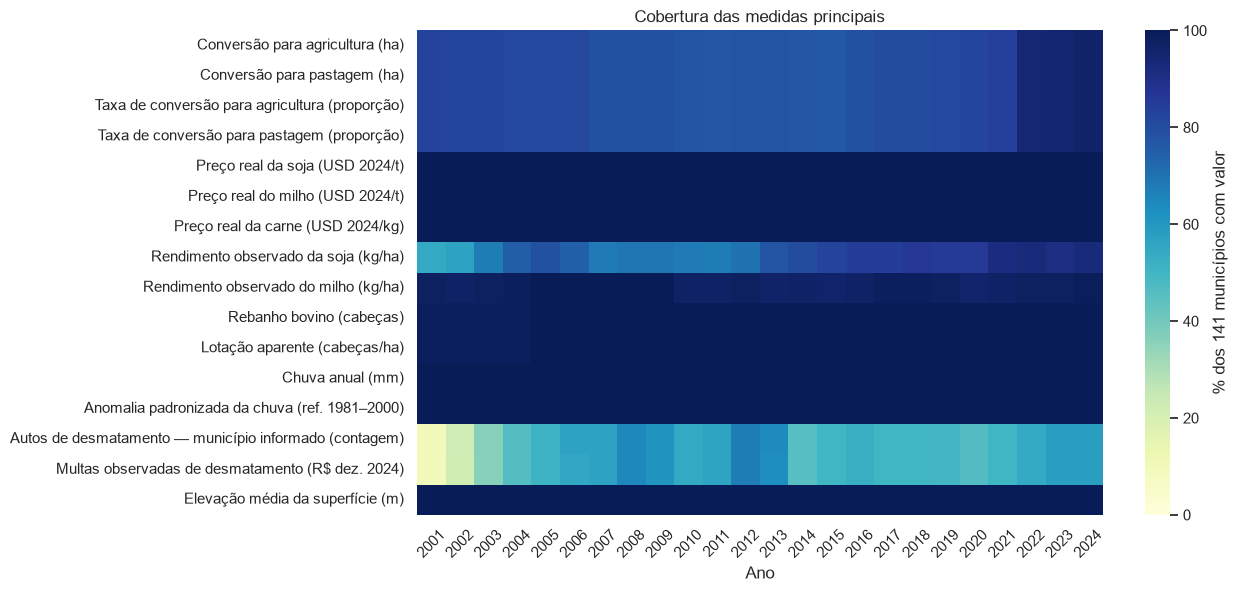

In [46]:
fig = mapa_cobertura(painel, PRINCIPAIS)
plt.show()
plt.close(fig)

In [47]:
display(frequencias_qualidade(painel, catalogo))

,coluna,n_validos,n_ausentes,n_valores_distintos,n_true,n_false
0,y_colecao,3384,0,1,<NA>,<NA>
1,y_malha,3384,0,1,<NA>,<NA>
2,y_mascara_id,3384,0,3384,<NA>,<NA>
3,y_area_total_ha,3384,0,583,<NA>,<NA>
4,y_area_valida_par_ha,3384,0,999,<NA>,<NA>
5,y_area_nao_valida_par_ha,3384,0,358,<NA>,<NA>
6,y_cobertura_completa,3384,0,2,2772,612
7,y_fracao_area_valida_par,3384,0,401,<NA>,<NA>
8,y_flag_denominador_zero,3384,0,1,0,3384
9,y_flag_denominador_ausente,3384,0,1,0,3384


## 5. Estatística descritiva completa das medidas

Cada coluna é resumida em sua unidade de observação: preços têm até **24 anos**, atributos fixos têm até **141 municípios**, e medidas anuais municipais têm até **3.384 pares**. Essa contagem não é o número de observações estatisticamente independentes.

Apresentamos oportunidades, valores válidos, ausências, zeros, negativos, média, desvio-padrão amostral, mínimo, P1/P5/P25/mediana/P75/P95/P99, máximo, assimetria e curtose excedente. A regra de 1,5 × IQR sinaliza extremos; não remove nem winsoriza dados. Valores negativos podem ser legítimos em anomalias e transformações. A formatação arredonda apenas a exibição.

In [48]:
descritiva = descrever_medidas(painel, catalogo)

In [49]:
assert set(descritiva.variavel) == set(catalogo.loc[catalogo.papel.eq("medida"), "coluna_painel"])

In [50]:
assert all(not resumo_por_fonte(descritiva, catalogo, nome).empty for nome in inventario.loc[inventario.papel_painel.str.startswith("incluída"), "nome"])

In [51]:
display(descritiva)

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,conversao_ha__agricultura,ha,município–ano,3384,2772,612,18.0851,265,0,297.6973,"1,015.3823",0.0000,0.0000,0.0000,3.1142,26.9875,173.3475,"1,244.5565","5,273.0864","18,222.2681",8.0799,88.2504,170.2334,377
1,conversao_ha__pastagem,ha,município–ano,3384,2772,612,18.0851,0,0,"3,257.5881","4,832.1764",0.9532,37.1933,113.3744,579.7612,"1,644.6794","3,769.3857","12,000.8732","24,037.6654","56,983.2254",3.8524,22.4379,"3,189.6245",247
2,taxa_conversao__agricultura,proporção (0–1),município–ano,3384,2772,612,18.0851,265,0,0.0011,0.0038,0.0000,0.0000,0.0000,0.0000,0.0001,0.0008,0.0047,0.0172,0.0800,10.0507,145.1068,0.0007,375
3,taxa_conversao__pastagem,proporção (0–1),município–ano,3384,2772,612,18.0851,0,0,0.0119,0.0143,0.0000,0.0007,0.0016,0.0043,0.0080,0.0141,0.0361,0.0636,0.2654,5.9476,70.8136,0.0098,207
4,y_nativa_inicial_ha,ha,município–ano,3384,3384,0,0.0000,0,0,"416,822.2591","495,642.2565","6,485.4199","8,190.0359","14,505.5147","100,895.1524","250,880.5144","438,459.5682","1,573,291.4862","2,280,406.6775","2,737,508.6963",2.0599,4.1173,"337,564.4158",456
5,preco_nominal_media_anual__carne_bovina,USD nominal/kg,ano,24,24,0,0.0000,0,0,3.8486,1.1652,2.1058,2.1066,2.1119,2.7204,4.1029,4.6917,5.5784,5.8606,5.9325,-0.0253,-1.1458,1.9712,0
6,preco_nominal_media_anual__milho,USD nominal/t,ano,24,24,0,0.0000,0,0,183.8403,66.7881,89.6500,91.7257,98.7638,146.3625,167.6333,230.5083,297.3996,314.1099,318.8000,0.5160,-0.6163,84.1458,0
7,preco_nominal_media_anual__soja,USD nominal/t,ano,24,24,0,0.0000,0,0,422.8299,129.0952,195.8333,199.7050,220.3667,353.4375,406.0833,525.7708,597.5417,657.5917,675.4167,0.0420,-0.6689,172.3333,0
8,preco_real_usd2024_media_anual__carne_bovina,USD 2024/kg,ano,24,24,0,0.0000,0,0,5.0936,0.9020,3.6269,3.6391,3.6872,4.3243,5.2740,5.7710,6.1565,6.5703,6.6876,-0.2326,-1.1565,1.4467,0
9,preco_real_usd2024_media_anual__milho,USD 2024/t,ano,24,24,0,0.0000,0,0,245.1992,73.9796,158.4982,158.5784,160.9746,190.3539,216.6793,275.6321,398.1314,407.4161,407.6199,0.9781,0.0232,85.2782,2


In [52]:
display(descritiva[["variavel", "unidade_observacao", "n_oportunidades", "n_validos", "n_ausentes", "n_zeros", "n_negativos"]])

,variavel,unidade_observacao,n_oportunidades,n_validos,n_ausentes,n_zeros,n_negativos
0,conversao_ha__agricultura,município–ano,3384,2772,612,265,0
1,conversao_ha__pastagem,município–ano,3384,2772,612,0,0
2,taxa_conversao__agricultura,município–ano,3384,2772,612,265,0
3,taxa_conversao__pastagem,município–ano,3384,2772,612,0,0
4,y_nativa_inicial_ha,município–ano,3384,3384,0,0,0
5,preco_nominal_media_anual__carne_bovina,ano,24,24,0,0,0
6,preco_nominal_media_anual__milho,ano,24,24,0,0,0
7,preco_nominal_media_anual__soja,ano,24,24,0,0,0
8,preco_real_usd2024_media_anual__carne_bovina,ano,24,24,0,0,0
9,preco_real_usd2024_media_anual__milho,ano,24,24,0,0,0


In [53]:
display(descritiva[["variavel", "unidade", "p25", "p75", "iqr", "n_fora_1_5_iqr"]])

,variavel,unidade,p25,p75,iqr,n_fora_1_5_iqr
0,conversao_ha__agricultura,ha,3.1142,173.3475,170.2334,377
1,conversao_ha__pastagem,ha,579.7612,"3,769.3857","3,189.6245",247
2,taxa_conversao__agricultura,proporção (0–1),0.0000,0.0008,0.0007,375
3,taxa_conversao__pastagem,proporção (0–1),0.0043,0.0141,0.0098,207
4,y_nativa_inicial_ha,ha,"100,895.1524","438,459.5682","337,564.4158",456
5,preco_nominal_media_anual__carne_bovina,USD nominal/kg,2.7204,4.6917,1.9712,0
6,preco_nominal_media_anual__milho,USD nominal/t,146.3625,230.5083,84.1458,0
7,preco_nominal_media_anual__soja,USD nominal/t,353.4375,525.7708,172.3333,0
8,preco_real_usd2024_media_anual__carne_bovina,USD 2024/kg,4.3243,5.7710,1.4467,0
9,preco_real_usd2024_media_anual__milho,USD 2024/t,190.3539,275.6321,85.2782,2


## 6. As 25 candidatas: resultados e pendências

Cada subseção mostra a contribuição daquela candidata. As mesmas medidas podem aparecer em mais de uma subseção quando os notebooks compartilham fontes. Isso não duplica colunas no painel. As tabelas adiadas são diagnósticos, não valores anuais estimados.

### 1. Y_conv

[Y_conv.ipynb](Y_conv.ipynb) — **Conversão bruta por destino**.

Selecionamos pixels que eram nativos em t−1 e passaram para agricultura ou pastagem em t. Somamos suas áreas em hectares, mantendo os dois destinos separados. É necessário observar as duas datas na mesma coleção, máscara e malha. Usamos mapas 10.1, pixels na grade original e os 141 territórios de 2023. Ano t identifica o intervalo dos mapas t−1 a t. A diferença de estoques não mede esse fluxo.

**Limite:** A área sem classificação é medida diretamente. Qualquer lacuna real mantém Y ausente; diferenças numéricas entre grandes somas não são confundidas com pixels ausentes. Zero só é aceito depois de verificar a matriz completa. O dado registra mudança entre mapas anuais e não informa a data exata da decisão ou sua causa.

In [54]:
display(resumo_por_fonte(descritiva, catalogo, 'Y_conv'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,conversao_ha__agricultura,ha,município–ano,3384,2772,612,18.0851,265,0,297.6973,"1,015.3823",0.0000,0.0000,0.0000,3.1142,26.9875,173.3475,"1,244.5565","5,273.0864","18,222.2681",8.0799,88.2504,170.2334,377
1,conversao_ha__pastagem,ha,município–ano,3384,2772,612,18.0851,0,0,"3,257.5881","4,832.1764",0.9532,37.1933,113.3744,579.7612,"1,644.6794","3,769.3857","12,000.8732","24,037.6654","56,983.2254",3.8524,22.4379,"3,189.6245",247
2,taxa_conversao__agricultura,proporção (0–1),município–ano,3384,2772,612,18.0851,265,0,0.0011,0.0038,0.0000,0.0000,0.0000,0.0000,0.0001,0.0008,0.0047,0.0172,0.0800,10.0507,145.1068,0.0007,375
3,taxa_conversao__pastagem,proporção (0–1),município–ano,3384,2772,612,18.0851,0,0,0.0119,0.0143,0.0000,0.0007,0.0016,0.0043,0.0080,0.0141,0.0361,0.0636,0.2654,5.9476,70.8136,0.0098,207
4,y_nativa_inicial_ha,ha,município–ano,3384,3384,0,0.0000,0,0,"416,822.2591","495,642.2565","6,485.4199","8,190.0359","14,505.5147","100,895.1524","250,880.5144","438,459.5682","1,573,291.4862","2,280,406.6775","2,737,508.6963",2.0599,4.1173,"337,564.4158",456


### 2. Y_tx-conv

[Y_tx-conv.ipynb](Y_tx-conv.ipynb) — **Taxas de conversão por destino**.

Dividimos cada conversão bruta pela vegetação nativa no início do mesmo intervalo. O numerador e o denominador vêm dos mesmos pixels válidos nos dois mapas. Para 2001, usamos o mapa inicial de 2000. A máscara e o denominador acompanham cada município–ano.

**Limite:** Denominador zero torna a taxa indefinida. Taxas inconsistentes não são cortadas em 1. A taxa mede a fração convertida do estoque disponível, não o efeito acumulado sobre toda a vegetação histórica. Cobertura incompleta mantém área convertida e taxa ausentes, sem extrapolar os pixels observados.

In [55]:
display(resumo_por_fonte(descritiva, catalogo, 'Y_tx-conv'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,conversao_ha__agricultura,ha,município–ano,3384,2772,612,18.0851,265,0,297.6973,"1,015.3823",0.0000,0.0000,0.0000,3.1142,26.9875,173.3475,"1,244.5565","5,273.0864","18,222.2681",8.0799,88.2504,170.2334,377
1,conversao_ha__pastagem,ha,município–ano,3384,2772,612,18.0851,0,0,"3,257.5881","4,832.1764",0.9532,37.1933,113.3744,579.7612,"1,644.6794","3,769.3857","12,000.8732","24,037.6654","56,983.2254",3.8524,22.4379,"3,189.6245",247
2,taxa_conversao__agricultura,proporção (0–1),município–ano,3384,2772,612,18.0851,265,0,0.0011,0.0038,0.0000,0.0000,0.0000,0.0000,0.0001,0.0008,0.0047,0.0172,0.0800,10.0507,145.1068,0.0007,375
3,taxa_conversao__pastagem,proporção (0–1),município–ano,3384,2772,612,18.0851,0,0,0.0119,0.0143,0.0000,0.0007,0.0016,0.0043,0.0080,0.0141,0.0361,0.0636,0.2654,5.9476,70.8136,0.0098,207
4,y_nativa_inicial_ha,ha,município–ano,3384,3384,0,0.0000,0,0,"416,822.2591","495,642.2565","6,485.4199","8,190.0359","14,505.5147","100,895.1524","250,880.5144","438,459.5682","1,573,291.4862","2,280,406.6775","2,737,508.6963",2.0599,4.1173,"337,564.4158",456


### 3. x1_psoja-pmilho

[x1_psoja-pmilho.ipynb](x1_psoja-pmilho.ipynb) — **Preços anuais, defasagens e exposição econômica**.

Preservamos soja e milho separados. Deflacionamos os preços mensais em USD quando o índice oficial está disponível, calculamos a média de 12 meses válidos e ligamos o ano t ao preço de t−1. Logs são calculados somente para preços positivos. As interações usam capacidade fixa, em cenários separados.

**Limite:** O preço anterior é uma exposição conhecida antes do intervalo anual, não uma expectativa observada. Preço × capacidade não é lucro líquido nem choque exógeno por definição.

In [56]:
display(resumo_por_fonte(descritiva, catalogo, 'x1_psoja-pmilho'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,preco_nominal_media_anual__milho,USD nominal/t,ano,24,24,0,0.0000,0,0,183.8403,66.7881,89.6500,91.7257,98.7638,146.3625,167.6333,230.5083,297.3996,314.1099,318.8000,0.5160,-0.6163,84.1458,0
1,preco_nominal_media_anual__soja,USD nominal/t,ano,24,24,0,0.0000,0,0,422.8299,129.0952,195.8333,199.7050,220.3667,353.4375,406.0833,525.7708,597.5417,657.5917,675.4167,0.0420,-0.6689,172.3333,0
2,preco_real_usd2024_media_anual__milho,USD 2024/t,ano,24,24,0,0.0000,0,0,245.1992,73.9796,158.4982,158.5784,160.9746,190.3539,216.6793,275.6321,398.1314,407.4161,407.6199,0.9781,0.0232,85.2782,2
3,preco_real_usd2024_media_anual__soja,USD 2024/t,ano,24,24,0,0.0000,0,0,564.8117,131.8161,346.9711,352.4209,377.7730,460.2616,524.4628,651.3098,757.9652,800.8299,813.2114,0.2770,-0.9678,191.0483,0
4,ln_preco_nominal_media_anual__milho,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,5.1498,0.3702,4.4959,4.5180,4.5927,4.9810,5.1217,5.4388,5.6950,5.7494,5.7646,-0.1032,-0.8098,0.4578,0
5,ln_preco_nominal_media_anual__soja,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,5.9975,0.3318,5.2773,5.2962,5.3922,5.8646,6.0066,6.2648,6.3928,6.4873,6.5153,-0.5903,-0.2601,0.4002,0
6,ln_preco_real_usd2024_media_anual__milho,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,5.4624,0.2819,5.0657,5.0662,5.0808,5.2489,5.3777,5.6178,5.9854,6.0098,6.0103,0.5674,-0.6643,0.3689,0
7,ln_preco_real_usd2024_media_anual__soja,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,6.3101,0.2360,5.8492,5.8644,5.9333,6.1318,6.2623,6.4788,6.6306,6.6852,6.7010,-0.0901,-0.8462,0.3470,0
8,preco_nominal_media_anual_lag1__milho,USD nominal/t,ano,24,24,0,0.0000,0,0,179.5882,69.5313,88.5500,88.8030,91.0037,119.3354,165.4917,230.5083,297.3996,314.1099,318.8000,0.5356,-0.7095,111.1729,0
9,preco_nominal_media_anual_lag1__soja,USD nominal/t,ano,24,24,0,0.0000,0,0,412.3889,135.7178,195.8333,199.5133,211.9583,298.5625,399.9583,525.7708,597.5417,657.5917,675.4167,0.1091,-0.8474,227.2083,0


### 4. x1a_pcarne

[x1a_pcarne.ipynb](x1a_pcarne.ipynb) — **Preço da carne na janela anterior**.

Calculamos médias anuais e ligamos o preço do ano anterior ao ano do painel. Mantemos a unidade USD/kg e distinguimos valor nominal e real. Não multiplicamos cabeças por preço por kg.

**Limite:** Preço internacional de carne não equivale ao preço local do boi. A exposição pecuária predeterminada continua uma decisão distinta; lotação contemporânea não a substitui.

In [57]:
display(resumo_por_fonte(descritiva, catalogo, 'x1a_pcarne'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,preco_nominal_media_anual__carne_bovina,USD nominal/kg,ano,24,24,0,0.0000,0,0,3.8486,1.1652,2.1058,2.1066,2.1119,2.7204,4.1029,4.6917,5.5784,5.8606,5.9325,-0.0253,-1.1458,1.9712,0
1,preco_real_usd2024_media_anual__carne_bovina,USD 2024/kg,ano,24,24,0,0.0000,0,0,5.0936,0.9020,3.6269,3.6391,3.6872,4.3243,5.2740,5.7710,6.1565,6.5703,6.6876,-0.2326,-1.1565,1.4467,0
2,ln_preco_nominal_media_anual__carne_bovina,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,1.2997,0.3247,0.7447,0.7451,0.7476,1.0008,1.4117,1.5457,1.7187,1.7680,1.7804,-0.4090,-1.1057,0.5450,0
3,ln_preco_real_usd2024_media_anual__carne_bovina,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,1.6121,0.1845,1.2884,1.2917,1.3049,1.4639,1.6628,1.7528,1.8175,1.8820,1.9003,-0.4439,-1.0982,0.2889,0
4,preco_nominal_media_anual_lag1__carne_bovina,USD nominal/kg,ano,24,24,0,0.0000,0,0,3.6817,1.1404,1.9258,1.9672,2.1063,2.6887,4.0692,4.5875,5.2984,5.5562,5.6200,-0.0611,-1.3237,1.8988,0
5,preco_real_usd2024_media_anual_lag1__carne_bovina,USD 2024/kg,ano,24,24,0,0.0000,0,0,4.9927,0.9390,3.5091,3.5362,3.6349,4.1120,5.1439,5.7024,6.1565,6.5703,6.6876,-0.1146,-1.2215,1.5904,0
6,ln_preco_nominal_media_anual_lag1__carne_bovina,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,1.2528,0.3334,0.6554,0.6759,0.7449,0.9891,1.4034,1.5233,1.6672,1.7147,1.7263,-0.3991,-1.2171,0.5342,0
7,ln_preco_real_usd2024_media_anual_lag1__carne_bovina,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,0,1.5903,0.1945,1.2554,1.2630,1.2906,1.4139,1.6376,1.7409,1.8175,1.8820,1.9003,-0.3323,-1.2141,0.3270,0
8,dln_preco_nominal_media_anual__carne_bovina,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,8,0.0469,0.1179,-0.1703,-0.1626,-0.1337,-0.0231,0.0267,0.1454,0.2216,0.2274,0.2281,-0.0513,-0.9410,0.1685,0
9,dln_preco_real_usd2024_media_anual__carne_bovina,adimensional (transformação/interação indicada no nome),ano,24,24,0,0.0000,0,13,0.0219,0.1141,-0.1783,-0.1753,-0.1598,-0.0405,-0.0109,0.1174,0.1990,0.2072,0.2089,0.0724,-0.8992,0.1579,0


### 5. x2_prodsoja-prodmilho

[x2_prodsoja-prodmilho.ipynb](x2_prodsoja-prodmilho.ipynb) — **Rendimento observado e conferência das unidades**.

Separamos soja e milho, preservamos o rendimento informado e conferimos produção e área colhida. A recomposição por produção/área usa toneladas para kg. Defasagens ligam anos exatos.

**Limite:** Rendimento ausente não vira zero. Produtividade observada pode responder a preços, clima e uso de insumos; não é automaticamente uma capacidade anterior à decisão.

In [58]:
display(resumo_por_fonte(descritiva, catalogo, 'x2_prodsoja-prodmilho'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,rendimento_medio_kg_ha__Milho (em grão),kg/ha,município–ano,3384,3318,66,1.9504,0,0,"4,219.0907","1,509.8424",600.0000,"1,500.0000","1,859.0000","3,000.0000","4,136.5000","5,490.2500","6,600.0000","7,200.0000","8,355.0000",0.1578,-1.0331,"2,490.2500",0
1,rendimento_medio_kg_ha__Soja (em grão),kg/ha,município–ano,3384,2615,769,22.7246,0,0,"3,116.5281",379.1877,900.0000,"1,920.2800","2,460.0000","2,992.0000","3,120.0000","3,300.0000","3,720.0000","3,900.0000","4,600.0000",-0.5321,1.9785,308.0000,271
2,rendimento_recalculado_kg_ha__Milho (em grão),kg/ha,município–ano,3384,3318,66,1.9504,0,0,"4,219.1804","1,509.8008",600.0000,"1,500.0000","1,859.6995","3,000.0000","4,136.8075","5,490.5811","6,600.0000","7,200.0000","8,354.7170",0.1577,-1.0330,"2,490.5811",0
3,rendimento_recalculado_kg_ha__Soja (em grão),kg/ha,município–ano,3384,2615,769,22.7246,0,0,"3,116.5809",379.1431,900.0000,"1,920.3111","2,460.0000","2,992.4572","3,120.0000","3,300.0000","3,720.0000","3,900.0050","4,600.0000",-0.5320,1.9792,307.5428,274
4,rendimento_medio_kg_ha_lag1__Milho (em grão),kg/ha,município–ano,3384,3304,80,2.3641,0,0,"4,082.4764","1,489.8899",600.0000,"1,500.0000","1,800.0000","3,000.0000","3,900.0000","5,400.0000","6,600.0000","7,124.9100","8,355.0000",0.2423,-0.9736,"2,400.0000",0
5,rendimento_medio_kg_ha_lag1__Soja (em grão),kg/ha,município–ano,3384,2550,834,24.6454,0,0,"3,103.9353",378.0783,900.0000,"1,919.0000","2,438.2500","2,951.5000","3,113.0000","3,300.0000","3,720.0000","3,900.0000","4,500.0000",-0.5886,1.9453,348.5000,183


### 6. x2a_hprodsoj-hprodmil

[x2a_hprodsoj-hprodmil.ipynb](x2a_hprodsoj-hprodmil.ipynb) — **Capacidade histórica anterior ao painel**.

Aplicamos a janela discutida de 1991–2000, com pelo menos 7 anos de rendimento válido por município e cultura. Calculamos a média dos anos válidos e guardamos a cobertura. A padronização usa uma única referência fixa.

**Limite:** Não cultivo e falta de registro não são rendimento zero. Os códigos históricos ainda exigem validação territorial; a tabela sinaliza essa limitação e a seleção de produtores históricos.

In [59]:
display(resumo_por_fonte(descritiva, catalogo, 'x2a_hprodsoj-hprodmil'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,capacidade_valor__milho__pam_1991_2000_min7,kg/ha,município,141,117,24,17.0213,0,0,"2,353.1639",561.0075,"1,355.2000","1,424.6440","1,561.1800","1,950.0000","2,285.1000","2,621.8000","3,439.6600","3,923.6480","4,453.8000",0.9356,1.3907,671.8000,4
1,capacidade_valor__soja__pam_1991_2000_min7,kg/ha,município,141,47,94,66.6667,0,0,"2,492.2381",175.2617,"2,117.1000","2,154.7740","2,217.0025","2,349.4500","2,489.0000","2,620.2000","2,715.5600","2,827.2040","2,913.5000",-0.0944,-0.5779,270.7500,0
2,capacidade_z__milho__pam_1991_2000_min7,adimensional (transformação/interação indicada no nome),município,141,117,24,17.0213,0,64,0.0000,1.0000,-1.7789,-1.6551,-1.4117,-0.7186,-0.1213,0.4788,1.9367,2.7994,3.7444,0.9356,1.3907,1.1975,4
3,capacidade_z__soja__pam_1991_2000_min7,adimensional (transformação/interação indicada no nome),município,141,47,94,66.6667,0,24,-0.0000,1.0000,-2.1404,-1.9255,-1.5704,-0.8147,-0.0185,0.7301,1.2742,1.9112,2.4036,-0.0944,-0.5779,1.5448,0
4,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7,adimensional (transformação/interação indicada no nome),município–ano,3384,2808,576,17.0213,0,1536,0.0000,5.4403,-10.6917,-9.4243,-7.6861,-3.9914,-0.6446,2.6900,10.9263,16.5510,22.5051,0.9278,1.3327,6.6814,85
5,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7,adimensional (transformação/interação indicada no nome),município–ano,3384,1128,2256,66.6667,0,576,-0.0000,6.2424,-14.3431,-13.4143,-10.0697,-5.1713,-0.1157,4.7203,8.1181,15.0636,16.1066,-0.0917,-0.6271,9.8916,0


### 7. x2b_yield-sojamilho

[x2b_yield-sojamilho.ipynb](x2b_yield-sojamilho.ipynb) — **Capacidade potencial GAEZ por cenário**.

Mantemos os rasters yx separados por cultura e nível de insumo. Padronizamos cada cenário entre municípios uma única vez e construímos exposições aos preços prévios. Não misturamos alto e baixo insumo.

**Limite:** A unidade original é kg de matéria seca/ha. Sem parâmetro validado de umidade, não calculamos receita comercial. A base de terras de 2010 impede presumir capacidade predeterminada sem auditoria.

In [60]:
display(resumo_por_fonte(descritiva, catalogo, 'x2b_yield-sojamilho'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,capacidade_valor__milho__gaez_yxHr0_mze,kg matéria seca/ha,município,141,141,0,0.0000,0,0,"3,303.2690",781.2915,"1,969.7150","2,296.1295","2,598.5666","2,863.5878","3,144.1850","3,467.7293","4,653.5594","6,813.4073","7,008.4429",2.4241,8.0597,604.1415,13
1,capacidade_valor__soja__gaez_yxHr0_soy,kg matéria seca/ha,município,141,141,0,0.0000,0,0,"2,921.5312",380.9300,"1,753.3467","2,030.8225","2,447.8825","2,595.8567","2,832.1627","3,270.3676","3,478.2677","3,664.0645","3,733.4172",0.0389,-0.3150,674.5109,0
2,capacidade_valor__milho__gaez_yxLr0_mze,kg matéria seca/ha,município,141,141,0,0.0000,0,0,890.8265,211.4491,389.4944,439.1098,567.0848,768.6625,869.0098,"1,008.3958","1,303.0057","1,453.4624","1,580.5651",0.5891,0.9752,239.7333,7
3,capacidade_valor__soja__gaez_yxLr0_soy,kg matéria seca/ha,município,141,141,0,0.0000,0,0,302.5749,70.1398,111.5800,124.0401,192.2177,268.4130,302.1815,343.3158,426.2941,480.9218,512.2292,0.0787,0.8677,74.9028,8
4,capacidade_z__milho__gaez_yxHr0_mze,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,91,-0.0000,1.0000,-1.7069,-1.2891,-0.9020,-0.5628,-0.2036,0.2105,1.7283,4.4927,4.7424,2.4241,8.0597,0.7733,13
5,capacidade_z__soja__gaez_yxHr0_soy,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,78,-0.0000,1.0000,-3.0667,-2.3382,-1.2434,-0.8549,-0.2346,0.9157,1.4615,1.9493,2.1313,0.0389,-0.3150,1.7707,0
6,capacidade_z__milho__gaez_yxLr0_mze,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,76,-0.0000,1.0000,-2.3709,-2.1363,-1.5311,-0.5777,-0.1032,0.5560,1.9493,2.6609,3.2620,0.5891,0.9752,1.1338,7
7,capacidade_z__soja__gaez_yxLr0_soy,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,71,-0.0000,1.0000,-2.7231,-2.5454,-1.5734,-0.4871,-0.0056,0.5809,1.7639,2.5427,2.9891,0.0787,0.8677,1.0679,8
8,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,0,2184,-0.0000,5.4442,-10.2588,-7.4043,-5.3695,-3.0978,-1.1275,1.1611,9.7132,24.8827,28.5032,2.4091,7.8659,4.2589,303
9,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,0,1872,-0.0000,6.2856,-20.5497,-18.0668,-7.7816,-5.3726,-1.4580,5.8869,9.6929,12.6364,14.2820,0.0386,-0.3297,11.2595,0


### 8. x2c_aptid-sojamilho

[x2c_aptid-sojamilho.ipynb](x2c_aptid-sojamilho.ipynb) — **Aptidão reescalada e exposição aos preços**.

Dividimos sx por 10.000 para facilitar leitura e padronizamos cada cenário fixo. Os produtos e os níveis de insumo permanecem identificados nas interações.

**Limite:** Reescalar não transforma aptidão em probabilidade, kg/ha ou receita. Os cenários são alternativas, não controles para inclusão simultânea automática.

In [61]:
display(resumo_por_fonte(descritiva, catalogo, 'x2c_aptid-sojamilho'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,capacidade_valor__milho__gaez_sxHr0_mze,índice 0–10.000,município,141,141,0,0.0000,0,0,"2,992.3791",538.7820,"1,807.5451","1,858.3109","2,331.8549","2,725.6149","3,036.6481","3,232.0978","3,578.6278","5,487.3901","5,615.8145",1.9312,9.0346,506.4829,9
1,capacidade_valor__soja__gaez_sxHr0_soy,índice 0–10.000,município,141,141,0,0.0000,0,0,"4,984.7285",689.4017,"2,957.9161","3,085.1755","3,786.3420","4,643.7729","5,035.0432","5,312.2977","6,129.3545","6,468.0536","6,490.3476",-0.3857,0.7292,668.5248,10
2,capacidade_valor__milho__gaez_sxLr0_mze,índice 0–10.000,município,141,141,0,0.0000,0,0,"2,219.0493",445.3703,"1,284.1328","1,415.8226","1,666.8461","1,907.3689","2,178.4002","2,520.5260","2,813.0243","3,922.5142","4,194.6546",1.2767,3.9908,613.1571,3
3,capacidade_valor__soja__gaez_sxLr0_soy,índice 0–10.000,município,141,141,0,0.0000,0,0,"2,134.3824",379.4547,"1,200.5592","1,423.1159","1,651.0432","1,815.6761","2,091.1006","2,411.3453","2,752.7248","2,968.9425","3,296.4481",0.3280,-0.3398,595.6691,0
4,capacidade_z__milho__gaez_sxHr0_mze,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,68,0.0000,1.0000,-2.1991,-2.1049,-1.2260,-0.4951,0.0822,0.4449,1.0881,4.6308,4.8692,1.9312,9.0346,0.9401,9
5,capacidade_z__soja__gaez_sxHr0_soy,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,59,0.0000,1.0000,-2.9400,-2.7554,-1.7383,-0.4946,0.0730,0.4751,1.6603,2.1516,2.1840,-0.3857,0.7292,0.9697,10
6,capacidade_z__milho__gaez_sxLr0_mze,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,79,-0.0000,1.0000,-2.0992,-1.8035,-1.2399,-0.6998,-0.0913,0.6769,1.3337,3.8248,4.4359,1.2767,3.9908,1.3767,3
7,capacidade_z__soja__gaez_sxLr0_soy,adimensional (transformação/interação indicada no nome),município,141,141,0,0.0000,0,72,-0.0000,1.0000,-2.4610,-1.8744,-1.2738,-0.8399,-0.1141,0.7299,1.6296,2.1994,3.0625,0.3280,-0.3398,1.5698,0
8,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,0,1632,0.0000,5.4442,-13.2173,-11.6429,-7.1506,-2.8442,0.4419,2.3632,6.5127,25.5556,29.2655,1.9192,8.8183,5.2075,180
9,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,0,1416,0.0000,6.2856,-19.7006,-17.7608,-10.9585,-3.2201,0.4570,3.0525,10.7217,13.6224,14.6346,-0.3825,0.6852,6.2726,216


### 9. x3_infracoes

[x3_infracoes.ipynb](x3_infracoes.ipynb) — **Autos pelo município informado**.

Conferimos o agregado original e construímos contagens temáticas a partir de identidades únicas. Flora e desmatamento são seleções alternativas. Usamos ano de lavratura e mantemos status desconhecidos visíveis.

**Limite:** Sem registros não se presume zero. Cobertura temática parcial é sinalizada. Autos descrevem registros administrativos, não eficácia institucional.

In [62]:
display(resumo_por_fonte(descritiva, catalogo, 'x3_infracoes'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,n_autos_observados__ibama_informada,contagem,município–ano,3384,2284,1100,32.5059,0,0,16.6392,30.6842,1.0000,1.0000,1.0000,2.0000,7.0000,18.0000,61.0000,151.1700,500.0000,6.0065,57.2599,16.0000,211
1,n_autos_flora__ibama_informada,contagem,município–ano,3384,2144,1240,36.6430,363,0,11.1479,21.3396,0.0000,0.0000,0.0000,1.0000,4.0000,11.2500,48.0000,107.1400,235.0000,4.4357,27.6564,10.2500,242
2,multas_flora_nominais_observadas__ibama_informada,R$ nominal,município–ano,3384,2143,1241,36.6726,363,0,"5,903,138.6528","16,342,513.2809",0.0000,0.0000,0.0000,"9,799.8000","372,036.0000","3,848,114.1000","30,247,390.2300","82,314,948.3000","264,948,096.5000",5.9954,53.9030,"3,838,314.3000",320
3,multas_flora_reais_observadas__ibama_informada,R$ dez. 2024,município–ano,3384,2143,1241,36.6726,363,0,"10,949,556.3017","29,064,251.4429",0.0000,0.0000,0.0000,"23,158.7130","741,252.4777","7,031,410.0701","57,597,978.2848","154,400,173.0587","476,417,423.7626",5.6245,49.6787,"7,008,251.3571",330
4,n_autos_desmatamento__ibama_informada,contagem,município–ano,3384,1711,1673,49.4385,231,0,6.7984,12.8832,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000,28.0000,71.9000,122.0000,4.2878,22.5293,6.0000,164
5,multas_desmatamento_nominais_observadas__ibama_informada,R$ nominal,município–ano,3384,1707,1677,49.5567,231,0,"5,181,813.6332","14,224,046.5673",0.0000,0.0000,0.0000,"12,015.0000","470,000.0000","3,821,462.5000","24,734,193.0000","66,502,468.0000","241,619,399.1000",6.8029,71.0739,"3,809,447.5000",244
6,multas_desmatamento_reais_observadas__ibama_informada,R$ dez. 2024,município–ano,3384,1707,1677,49.5567,231,0,"9,444,694.4957","25,174,043.1342",0.0000,0.0000,0.0000,"29,306.0353","888,362.5781","7,050,975.9936","45,283,602.3690","134,384,512.8485","435,045,235.2036",6.3349,65.0008,"7,021,669.9583",237
7,n_autos_flora_lag1__ibama_informada,contagem,município–ano,3384,2113,1271,37.5591,347,0,11.3549,21.6260,0.0000,0.0000,0.0000,1.0000,4.0000,12.0000,48.4000,107.7600,235.0000,4.3588,26.5753,11.0000,221
8,n_autos_desmatamento_lag1__ibama_informada,contagem,município–ano,3384,1641,1743,51.5071,202,0,6.9756,13.1032,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000,29.0000,73.8000,122.0000,4.2116,21.6475,6.0000,163
9,multas_flora_reais_observadas_lag1__ibama_informada,R$ dez. 2024,município–ano,3384,2112,1272,37.5887,347,0,"10,865,538.0004","29,099,347.2301",0.0000,0.0000,0.0000,"25,007.9071","679,173.5113","6,831,506.0421","57,640,315.6705","154,558,507.2373","476,417,423.7626",5.6524,50.0807,"6,806,498.1350",326


### 10. x3a_infracoes

[x3a_infracoes.ipynb](x3a_infracoes.ipynb) — **Autos pela localização espacial**.

Associamos identidades às coordenadas já reprocessadas na malha de 141 municípios. Construímos as mesmas seleções temáticas para comparar com o município informado.

**Limite:** A amostra geocodificada tem cobertura própria. Não somamos a contagem espacial à informada, pois ambas podem representar os mesmos autos.

In [63]:
display(resumo_por_fonte(descritiva, catalogo, 'x3a_infracoes'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,n_autos_observados__ibama_espacial,contagem,município–ano,3384,1828,1556,45.9811,0,0,12.7484,24.1640,1.0000,1.0000,1.0000,2.0000,5.0000,14.0000,47.6500,111.0000,596.0000,9.8257,193.8439,12.0000,178
1,n_autos_flora__ibama_espacial,contagem,município–ano,3384,1760,1624,47.9905,295,0,9.2108,17.5687,0.0000,0.0000,0.0000,1.0000,3.0000,9.0000,39.0500,92.4100,210.0000,4.4224,27.1305,8.0000,206
2,multas_flora_nominais_observadas__ibama_espacial,R$ nominal,município–ano,3384,1759,1625,48.0201,295,0,"6,377,343.0396","17,251,201.6190",0.0000,0.0000,0.0000,"11,407.5000","516,500.0000","4,315,000.0000","32,318,400.2400","88,288,483.8800","264,950,463.9000",5.9425,51.9425,"4,303,592.5000",261
3,multas_flora_reais_observadas__ibama_espacial,R$ dez. 2024,município–ano,3384,1759,1625,48.0201,295,0,"11,277,408.7256","29,520,233.5785",0.0000,0.0000,0.0000,"27,471.8467","905,745.3377","7,835,487.7360","57,353,274.3312","151,622,652.6652","476,435,920.9144",5.8465,54.0174,"7,808,015.8893",257
4,n_autos_desmatamento__ibama_espacial,contagem,município–ano,3384,1684,1700,50.2364,371,0,6.1039,12.5759,0.0000,0.0000,0.0000,1.0000,2.0000,6.0000,26.0000,67.5100,122.0000,4.4943,24.9333,5.0000,187
5,multas_desmatamento_nominais_observadas__ibama_espacial,R$ nominal,município–ano,3384,1682,1702,50.2955,371,0,"4,816,109.7418","13,984,353.3669",0.0000,0.0000,0.0000,"3,000.0000","379,025.0000","3,243,750.0000","22,474,822.8080","62,158,682.5000","241,939,399.1000",7.3688,80.7082,"3,240,750.0000",249
6,multas_desmatamento_reais_observadas__ibama_espacial,R$ dez. 2024,município–ano,3384,1682,1702,50.2955,371,0,"8,556,977.9832","23,847,983.7274",0.0000,0.0000,0.0000,"6,331.8638","694,399.7880","6,093,918.9260","42,919,579.9235","121,956,890.5099","435,619,256.5055",7.0310,80.7515,"6,087,587.0621",240
7,n_autos_flora_lag1__ibama_espacial,contagem,município–ano,3384,1684,1700,50.2364,277,0,9.4157,17.8857,0.0000,0.0000,0.0000,1.0000,3.0000,10.0000,42.0000,93.1700,210.0000,4.3464,26.1164,9.0000,178
8,n_autos_desmatamento_lag1__ibama_espacial,contagem,município–ano,3384,1610,1774,52.4232,347,0,6.2627,12.8187,0.0000,0.0000,0.0000,1.0000,2.0000,6.0000,27.5500,69.7300,122.0000,4.4038,23.8497,5.0000,185
9,multas_flora_reais_observadas_lag1__ibama_espacial,R$ dez. 2024,município–ano,3384,1683,1701,50.2660,277,0,"11,455,482.6450","29,917,890.9870",0.0000,0.0000,0.0000,"27,543.7845","871,903.6720","7,866,007.1735","58,136,307.2997","154,099,576.7591","476,435,920.9144",5.8050,53.1552,"7,838,463.3890",249


### 11. x3b_infracoes

[x3b_infracoes.ipynb](x3b_infracoes.ipynb) — **Seleção temática e agregação dos eventos**.

A categoria Flora fornece uma seleção ampla; o campo de tema de área identifica registros de desmatamento. Conferimos IDs, datas e localização antes de contar. Situação atual não é tratada como situação histórica.

**Limite:** As duas seleções não são somáveis. Datas do fato ausentes não são preenchidas silenciosamente com lavratura; cada data mede um momento diferente.

In [64]:
display(resumo_por_fonte(descritiva, catalogo, 'x3b_infracoes'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,n_autos_observados__ibama_informada,contagem,município–ano,3384,2284,1100,32.5059,0,0,16.6392,30.6842,1.0000,1.0000,1.0000,2.0000,7.0000,18.0000,61.0000,151.1700,500.0000,6.0065,57.2599,16.0000,211
1,n_autos_flora__ibama_informada,contagem,município–ano,3384,2144,1240,36.6430,363,0,11.1479,21.3396,0.0000,0.0000,0.0000,1.0000,4.0000,11.2500,48.0000,107.1400,235.0000,4.4357,27.6564,10.2500,242
2,multas_flora_nominais_observadas__ibama_informada,R$ nominal,município–ano,3384,2143,1241,36.6726,363,0,"5,903,138.6528","16,342,513.2809",0.0000,0.0000,0.0000,"9,799.8000","372,036.0000","3,848,114.1000","30,247,390.2300","82,314,948.3000","264,948,096.5000",5.9954,53.9030,"3,838,314.3000",320
3,multas_flora_reais_observadas__ibama_informada,R$ dez. 2024,município–ano,3384,2143,1241,36.6726,363,0,"10,949,556.3017","29,064,251.4429",0.0000,0.0000,0.0000,"23,158.7130","741,252.4777","7,031,410.0701","57,597,978.2848","154,400,173.0587","476,417,423.7626",5.6245,49.6787,"7,008,251.3571",330
4,n_autos_desmatamento__ibama_informada,contagem,município–ano,3384,1711,1673,49.4385,231,0,6.7984,12.8832,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000,28.0000,71.9000,122.0000,4.2878,22.5293,6.0000,164
5,multas_desmatamento_nominais_observadas__ibama_informada,R$ nominal,município–ano,3384,1707,1677,49.5567,231,0,"5,181,813.6332","14,224,046.5673",0.0000,0.0000,0.0000,"12,015.0000","470,000.0000","3,821,462.5000","24,734,193.0000","66,502,468.0000","241,619,399.1000",6.8029,71.0739,"3,809,447.5000",244
6,multas_desmatamento_reais_observadas__ibama_informada,R$ dez. 2024,município–ano,3384,1707,1677,49.5567,231,0,"9,444,694.4957","25,174,043.1342",0.0000,0.0000,0.0000,"29,306.0353","888,362.5781","7,050,975.9936","45,283,602.3690","134,384,512.8485","435,045,235.2036",6.3349,65.0008,"7,021,669.9583",237
7,n_autos_flora_lag1__ibama_informada,contagem,município–ano,3384,2113,1271,37.5591,347,0,11.3549,21.6260,0.0000,0.0000,0.0000,1.0000,4.0000,12.0000,48.4000,107.7600,235.0000,4.3588,26.5753,11.0000,221
8,n_autos_desmatamento_lag1__ibama_informada,contagem,município–ano,3384,1641,1743,51.5071,202,0,6.9756,13.1032,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000,29.0000,73.8000,122.0000,4.2116,21.6475,6.0000,163
9,multas_flora_reais_observadas_lag1__ibama_informada,R$ dez. 2024,município–ano,3384,2112,1272,37.5887,347,0,"10,865,538.0004","29,099,347.2301",0.0000,0.0000,0.0000,"25,007.9071","679,173.5113","6,831,506.0421","57,640,315.6705","154,558,507.2373","476,417,423.7626",5.6524,50.0807,"6,806,498.1350",326


### 12. x3c_infracoes

[x3c_infracoes.ipynb](x3c_infracoes.ipynb) — **Qualidade da associação territorial**.

Comparamos códigos somente quando as duas localizações estão disponíveis. Calculamos divergência entre os casos comparáveis e medimos separadamente a falta de localização.

**Limite:** Denominador zero deixa a taxa ausente. Este é um diagnóstico de mensuração, não uma variável adicional de fiscalização.

In [65]:
display(fontes["x3c_infracoes"]["tabelas"]["qualidade_geocodificacao"])

,ano,n_registros,n_ids_ausentes,n_ids_com_codigo_informado_valido,n_ids_com_espacial_valido,n_ids_sem_espacial_valido,fracao_sem_associacao_espacial,n_comparaveis,n_divergentes,taxa_divergencia,n_tipo_ausente,n_area_tema_ausente,fracao_tipo_preenchido,fracao_area_tema_preenchido,n_status_atual_ausente,n_data_fato_ausente
0,2001,1453,0,1453,14,1439,0.9904,14,4,0.2857,953,1420,0.3441,0.0227,1453,1453
1,2002,1913,0,1913,47,1866,0.9754,47,8,0.1702,1009,1819,0.4726,0.0491,1913,1913
2,2003,1863,0,1863,108,1755,0.9420,108,6,0.0556,996,1693,0.4654,0.0913,1863,1863
3,2004,2223,0,2223,265,1958,0.8808,265,57,0.2151,1025,1853,0.5389,0.1664,2223,2223
4,2005,2204,0,2204,382,1822,0.8267,382,62,0.1623,532,1692,0.7586,0.2323,2204,2204
5,2006,1971,0,1971,689,1282,0.6504,689,81,0.1176,269,1226,0.8635,0.3780,1971,1971
6,2007,2368,0,2368,1125,1243,0.5249,1125,110,0.0978,393,1124,0.8340,0.5253,2368,2368
7,2008,2365,0,2365,1529,836,0.3535,1529,118,0.0772,345,876,0.8541,0.6296,2365,2365
8,2009,2057,0,2057,1246,811,0.3943,1246,73,0.0586,9,871,0.9956,0.5766,2057,2057
9,2010,1451,0,1451,961,490,0.3377,961,28,0.0291,3,456,0.9979,0.6857,1451,1451


In [66]:
display(fontes["x3c_infracoes"]["tabelas"]["qualidade_geocodificacao"].drop(columns="ano").describe().T)

,count,mean,std,min,25%,50%,75%,max
n_registros,24.0000,"1,590.8750",543.2650,633.0000,"1,328.5000","1,498.0000","2,067.0000","2,368.0000"
n_ids_ausentes,24.0000,7.3750,14.0428,0.0000,0.0000,0.0000,2.5000,41.0000
n_ids_com_codigo_informado_valido,24.0000,"1,583.5000",554.1665,608.0000,"1,328.5000","1,493.0000","2,067.0000","2,368.0000"
n_ids_com_espacial_valido,24.0000,971.0000,584.8332,14.0000,573.7500,"1,043.0000","1,309.5000","2,152.0000"
n_ids_sem_espacial_valido,24.0000,612.5000,716.8458,9.0000,36.5000,147.5000,"1,252.7500","1,958.0000"
fracao_sem_associacao_espacial,24.0000,0.3275,0.3573,0.0113,0.0343,0.1540,0.5563,0.9904
n_comparaveis,24.0000,971.0000,584.8332,14.0000,573.7500,"1,043.0000","1,309.5000","2,152.0000"
n_divergentes,24.0000,88.1667,109.0124,4.0000,46.0000,58.0000,77.2500,522.0000
taxa_divergencia,24.0000,0.1010,0.0698,0.0291,0.0456,0.0797,0.1227,0.2857
n_tipo_ausente,24.0000,231.8333,379.2536,0.0000,0.0000,4.5000,357.0000,"1,025.0000"


### 13. x3d_infracoes

[x3d_infracoes.ipynb](x3d_infracoes.ipynb) — **Valores autuados em moeda constante**.

Usamos o valor de cada auto, a data de lavratura e o IPCA mensal disponível. Depois somamos por município, ano e seleção temática, conservando a informação sobre valores ausentes.

**Limite:** Soma parcial não é total completo; o indicador permanece visível. Multa autuada não significa multa paga, nem efeito dissuasório identificado.

In [67]:
display(resumo_por_fonte(descritiva, catalogo, 'x3d_infracoes'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,n_autos_observados__ibama_informada,contagem,município–ano,3384,2284,1100,32.5059,0,0,16.6392,30.6842,1.0000,1.0000,1.0000,2.0000,7.0000,18.0000,61.0000,151.1700,500.0000,6.0065,57.2599,16.0000,211
1,n_autos_flora__ibama_informada,contagem,município–ano,3384,2144,1240,36.6430,363,0,11.1479,21.3396,0.0000,0.0000,0.0000,1.0000,4.0000,11.2500,48.0000,107.1400,235.0000,4.4357,27.6564,10.2500,242
2,multas_flora_nominais_observadas__ibama_informada,R$ nominal,município–ano,3384,2143,1241,36.6726,363,0,"5,903,138.6528","16,342,513.2809",0.0000,0.0000,0.0000,"9,799.8000","372,036.0000","3,848,114.1000","30,247,390.2300","82,314,948.3000","264,948,096.5000",5.9954,53.9030,"3,838,314.3000",320
3,multas_flora_reais_observadas__ibama_informada,R$ dez. 2024,município–ano,3384,2143,1241,36.6726,363,0,"10,949,556.3017","29,064,251.4429",0.0000,0.0000,0.0000,"23,158.7130","741,252.4777","7,031,410.0701","57,597,978.2848","154,400,173.0587","476,417,423.7626",5.6245,49.6787,"7,008,251.3571",330
4,n_autos_desmatamento__ibama_informada,contagem,município–ano,3384,1711,1673,49.4385,231,0,6.7984,12.8832,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000,28.0000,71.9000,122.0000,4.2878,22.5293,6.0000,164
5,multas_desmatamento_nominais_observadas__ibama_informada,R$ nominal,município–ano,3384,1707,1677,49.5567,231,0,"5,181,813.6332","14,224,046.5673",0.0000,0.0000,0.0000,"12,015.0000","470,000.0000","3,821,462.5000","24,734,193.0000","66,502,468.0000","241,619,399.1000",6.8029,71.0739,"3,809,447.5000",244
6,multas_desmatamento_reais_observadas__ibama_informada,R$ dez. 2024,município–ano,3384,1707,1677,49.5567,231,0,"9,444,694.4957","25,174,043.1342",0.0000,0.0000,0.0000,"29,306.0353","888,362.5781","7,050,975.9936","45,283,602.3690","134,384,512.8485","435,045,235.2036",6.3349,65.0008,"7,021,669.9583",237
7,n_autos_flora_lag1__ibama_informada,contagem,município–ano,3384,2113,1271,37.5591,347,0,11.3549,21.6260,0.0000,0.0000,0.0000,1.0000,4.0000,12.0000,48.4000,107.7600,235.0000,4.3588,26.5753,11.0000,221
8,n_autos_desmatamento_lag1__ibama_informada,contagem,município–ano,3384,1641,1743,51.5071,202,0,6.9756,13.1032,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000,29.0000,73.8000,122.0000,4.2116,21.6475,6.0000,163
9,multas_flora_reais_observadas_lag1__ibama_informada,R$ dez. 2024,município–ano,3384,2112,1272,37.5887,347,0,"10,865,538.0004","29,099,347.2301",0.0000,0.0000,0.0000,"25,007.9071","679,173.5113","6,831,506.0421","57,640,315.6705","154,558,507.2373","476,417,423.7626",5.6524,50.0807,"6,806,498.1350",326


### 14. x3e_infracoes

[x3e_infracoes.ipynb](x3e_infracoes.ipynb) — **Diagnóstico dos embargos e exclusão temporária**.

Documentamos identidades, datas e cobertura do histórico. O plano mantém esta fonte fora do painel principal até reconstruir emissão e trajetória de situação com unidades verificadas.

**Limite:** Não criamos contagem anual final ou área embargada a partir de linhas do histórico. O arquivo de pendências registra os insumos necessários para liberar o cálculo.

In [68]:
display(fontes['x3e_infracoes']["tabelas"]["pendencias"])

,candidato,situacao,motivo,medida_final_construida,n_linhas,n_ids_distintos_cadastrados,n_ids_datas_embargo_conflitantes,n_linhas_coordenadas
0,x3e_infracoes,adiado,"Reconstruir identidade, data original, trajetória de status e localização; validar unidade de ár...",False,69269,12760,3044,3462


### 15. x4_pecuaria

[x4_pecuaria.ipynb](x4_pecuaria.ipynb) — **Rebanho e defasagem de calendário**.

Preservamos o estoque bovino anual e juntamos o valor do ano anterior pelo código e pelo ano. Não somamos estoques ao longo dos anos.

**Limite:** Rebanho mede cabeças, não produtividade. Mesmo o rebanho anterior pode refletir incentivos passados; a defasagem não garante exogeneidade.

In [69]:
display(resumo_por_fonte(descritiva, catalogo, 'x4_pecuaria'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,efetivo_bovino,cabeças,município–ano,3384,3376,8,0.2364,0,0,"203,003.9129","191,570.4386","4,115.0000","13,923.2500","26,020.2500","69,973.0000","138,886.0000","281,298.0000","583,082.2500","945,328.2500","1,399,931.0000",1.9932,5.0619,"211,325.0000",161
1,efetivo_bovino_lag1,cabeças,município–ano,3384,3361,23,0.6797,0,0,"199,765.6572","188,578.2026","4,115.0000","13,902.2000","25,443.0000","69,348.0000","137,084.0000","275,769.0000","562,410.0000","943,361.0000","1,399,931.0000",1.9901,5.0206,"206,421.0000",158


### 16. x4a_pecuaria

[x4a_pecuaria.ipynb](x4a_pecuaria.ipynb) — **Lotação aparente de pastagens**.

Somamos a pastagem da classe 15 sem sobrepor biomas e dividimos o estoque bovino pela área. Conservamos numerador, denominador e indicadores de ausência para conferir a razão.

**Limite:** Pastagem nula gera medida indefinida. Denominadores pequenos ficam visíveis. Cabeças/ha não mede produção de carne, ganho de peso ou lucro.

In [70]:
display(resumo_por_fonte(descritiva, catalogo, 'x4a_pecuaria'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,lotacao_cabecas_ha,cabeças/ha,município–ano,3384,3376,8,0.2364,0,0,1.4708,0.6939,0.0693,0.3743,0.6879,1.0670,1.3974,1.7414,2.4237,4.0274,8.4913,3.2979,21.9419,0.6745,93


### 17. x5_cobertura_terra

[x5_cobertura_terra.ipynb](x5_cobertura_terra.ipynb) — **Vegetação disponível no início do período**.

Reutilizamos as colunas de estoque e participação que já representam o ano anterior. Registramos denominador nulo ou ausente sem deslocar a série outra vez.

**Limite:** O denominador candidato só pode formar a taxa após conferir a máscara das transições. Não é incluído automaticamente como controle adicional à taxa.

In [71]:
display(resumo_por_fonte(descritiva, catalogo, 'x5_cobertura_terra'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,native_veg_ha_lag1,ha,município–ano,3384,3384,0,0.0000,0,0,"416,823.7350","495,643.5988","6,484.7202","8,190.1390","14,504.5549","100,898.7088","250,878.5188","438,465.8904","1,573,290.4517","2,280,411.2117","2,737,545.0693",2.0599,4.1173,"337,567.1816",456
1,native_veg_share_lag1,proporção (0–1),município–ano,3384,3384,0,0.0000,0,0,0.5448,0.1969,0.0727,0.1157,0.2163,0.4133,0.5540,0.6812,0.8703,0.9212,0.9790,-0.1068,-0.6554,0.2680,0


### 18. x5a_cobertura_terra

[x5a_cobertura_terra.ipynb](x5a_cobertura_terra.ipynb) — **Áreas e participações dos usos instalados**.

Agrupamos classes sem sobreposição para agricultura e pastagem. Conferimos a presença dos estratos esperados antes de somar e produzimos participações e defasagens exatas.

**Limite:** Área colhida de soja e milho pode usar o mesmo terreno em sucessão. Estoques instalados e seus saldos não substituem as transições de vegetação nativa.

In [72]:
display(resumo_por_fonte(descritiva, catalogo, 'x5a_cobertura_terra'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,nativa_ha,ha,município–ano,3384,3384,0,0.0000,0,0,"413,726.3048","493,058.4345","6,484.7202","7,869.8080","14,427.6159","98,949.8520","248,850.6657","436,483.9132","1,569,907.0893","2,278,801.6641","2,721,687.7694",2.0620,4.1120,"337,534.0612",452
1,agricultura_ha,ha,município–ano,3384,3384,0,0.0000,1,0,"66,727.9564","106,019.9549",0.0000,10.5381,59.8555,"1,816.0447","17,843.1921","79,620.6985","309,017.4809","442,766.3758","608,983.6513",2.3290,5.7346,"77,804.6539",390
2,pastagem_ha,ha,município–ano,3384,3384,0,0.0000,0,0,"144,283.6287","121,460.8791","3,958.1767","9,807.0399","20,705.0573","54,416.9575","111,317.9204","202,750.4526","381,915.2322","576,329.7325","683,014.5130",1.5606,2.8931,"148,333.4951",112
3,nativa_share,proporção (0–1),município–ano,3384,3384,0,0.0000,0,0,0.5400,0.1956,0.0727,0.1146,0.2146,0.4103,0.5496,0.6752,0.8688,0.9190,0.9734,-0.0959,-0.6396,0.2649,0
4,agricultura_share,proporção (0–1),município–ano,3384,3384,0,0.0000,1,0,0.1170,0.1556,0.0000,0.0000,0.0002,0.0050,0.0470,0.1655,0.4836,0.6391,0.6669,1.6808,2.1631,0.1604,264
5,pastagem_share,proporção (0–1),município–ano,3384,3384,0,0.0000,0,0,0.3145,0.2019,0.0116,0.0216,0.0412,0.1507,0.2970,0.4248,0.7027,0.8588,0.9117,0.7179,0.0129,0.2742,72
6,nativa_ha_lag1,ha,município–ano,3384,3384,0,0.0000,0,0,"416,823.7350","495,643.5988","6,484.7202","8,190.1390","14,504.5549","100,898.7088","250,878.5188","438,465.8904","1,573,290.4517","2,280,411.2117","2,737,545.0693",2.0599,4.1173,"337,567.1816",456
7,agricultura_ha_lag1,ha,município–ano,3384,3384,0,0.0000,1,0,"64,451.7871","104,419.3801",0.0000,8.6458,53.0415,"1,600.2141","16,151.8437","74,939.6255","303,005.3218","439,218.5954","608,255.1371",2.3836,6.0505,"73,339.4114",403
8,pastagem_ha_lag1,ha,município–ano,3384,3384,0,0.0000,0,0,"143,597.8246","120,347.8166","3,958.1767","9,979.8555","21,048.8683","54,470.6599","111,152.0279","202,325.2936","376,303.5283","570,792.9965","683,014.5130",1.5520,2.8613,"147,854.6337",112
9,nativa_share_lag1,proporção (0–1),município–ano,3384,3384,0,0.0000,0,0,0.5448,0.1969,0.0727,0.1157,0.2163,0.4133,0.5540,0.6812,0.8703,0.9212,0.9790,-0.1068,-0.6554,0.2680,0


### 19. x6_biomas

[x6_biomas.ipynb](x6_biomas.ipynb) — **Frações de bioma e heterogeneidade**.

Preservamos as frações de Amazônia, Cerrado e Pantanal, incluindo municípios mistos. Geramos interações com exposição econômica para Cerrado e Pantanal; Amazônia é a referência.

**Limite:** As frações são estáticas e seus níveis são absorvidos por efeitos fixos municipais. Não incluir a exposição e todas as frações interagidas sem conferir redundância.

In [73]:
display(resumo_por_fonte(descritiva, catalogo, 'x6_biomas'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,biome_amazonia_share_i,proporção (0–1),município,141,141,0,0.0000,44,0,0.5291,0.4507,0.0000,0.0000,0.0000,0.0000,0.7111,1.0000,1.0000,1.0000,1.0000,-0.1471,-1.8472,1.0000,0
1,biome_cerrado_share_i,proporção (0–1),município,141,141,0,0.0000,45,0,0.4425,0.4444,0.0000,0.0000,0.0000,0.0000,0.2526,1.0000,1.0000,1.0000,1.0000,0.2589,-1.7800,1.0000,0
2,biome_pantanal_share_i,proporção (0–1),município,141,141,0,0.0000,128,0,0.0284,0.1384,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0956,0.7691,0.9974,5.5636,31.2480,0.0000,13
3,exposicao_real_x_cerrado__milho__pam_1991_2000_min7,adimensional (transformação/interação indicada no nome),município–ano,3384,2808,576,17.0213,840,888,0.8784,4.4061,-9.9835,-8.3421,-5.6351,-0.1935,-0.0000,0.9759,10.5685,16.5510,22.5051,1.5380,4.3694,1.1693,849
4,exposicao_real_x_cerrado__soja__pam_1991_2000_min7,adimensional (transformação/interação indicada no nome),município–ano,3384,1128,2256,66.6667,72,528,0.4316,5.5859,-14.3431,-13.4143,-10.0697,-2.0120,-0.0000,4.2305,8.1144,15.0636,16.1066,-0.2268,0.3440,6.2426,48
5,exposicao_real_x_cerrado__milho__gaez_sxHr0_mze,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,1080,1056,-0.1404,2.2111,-7.3684,-6.4080,-4.9434,-0.0465,0.0000,0.4389,3.0504,6.0549,11.5086,0.0711,4.5932,0.4855,1206
6,exposicao_real_x_cerrado__soja__gaez_sxHr0_soy,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,1080,816,0.4334,3.2832,-9.4671,-8.3022,-3.8762,-0.0000,0.0000,0.4738,7.9666,13.2052,14.6346,1.2212,5.0983,0.4738,1171
7,exposicao_real_x_cerrado__milho__gaez_sxLr0_mze,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,1080,1128,-0.3031,2.9864,-12.1320,-7.5069,-6.0024,-0.3911,-0.0000,0.5782,4.5499,7.5029,8.6428,-0.3544,1.3864,0.9693,1223
8,exposicao_real_x_cerrado__soja__gaez_sxLr0_soy,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,1080,1080,-0.2094,3.9012,-15.3009,-13.6685,-7.0467,-0.9604,0.0000,0.7107,6.6220,12.3584,14.1695,-0.0103,3.2536,1.6711,882
9,exposicao_real_x_cerrado__milho__gaez_yxHr0_mze,adimensional (transformação/interação indicada no nome),município–ano,3384,3384,0,0.0000,1080,1272,0.1289,2.8463,-7.2171,-6.3464,-4.5811,-0.4275,0.0000,0.2413,6.0672,9.6679,13.4832,1.1679,3.9535,0.6688,1111


### 20. x7_custo-soja

[x7_custo-soja.ipynb](x7_custo-soja.ipynb) — **Custos de soja: insumos para construção posterior**.

Registramos cobertura das células e os campos necessários para uma série comparável: localidade, tecnologia, safra, categoria de custo, moeda e unidade.

**Limite:** Conforme o plano, a fonte fica fora do painel principal. Não misturamos R$/ha com R$/saca nem atribuímos o custo de poucas localidades a todos os municípios.

In [74]:
display(fontes['x7_custo-soja']["tabelas"]["pendencias"])

,campo_necessario
0,localidade
1,tecnologia
2,safra
3,ano
4,categoria_custo
5,unidade
6,moeda
7,metodologia
8,valor_custo_validado


In [75]:
display(fontes['x7_custo-soja']["tabelas"]["cobertura_celulas"])

,arquivo_origem,aba,n_celulas
0,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2006,145
1,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2007,145
2,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2008,145
3,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2009,145
4,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2010,145
5,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2011,299
6,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2012,299
7,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2013,299
8,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2014,299
9,serie-historica-custos-soja-1997-a-2026.xls,C. Novo do Parecis-MT-2015,299


### 21. x7_custo-milho-s1

[x7_custo-milho-s1.ipynb](x7_custo-milho-s1.ipynb) — **Custos de milho de primeira safra: cobertura e pendências**.

Mantemos primeira safra separada. Documentamos a cobertura observada e a necessidade de mapear as células antes de interpretar números como custos.

**Limite:** As abas identificadas terminam em 2013. Não prolongamos a série até 2024 por preenchimento nem criamos uma margem sem preços e quantidades compatíveis.

In [76]:
display(fontes['x7_custo-milho-s1']["tabelas"]["pendencias"])

,campo_necessario
0,localidade
1,tecnologia
2,safra
3,ano
4,categoria_custo
5,unidade
6,moeda
7,metodologia
8,valor_custo_validado


In [77]:
display(fontes['x7_custo-milho-s1']["tabelas"]["cobertura_celulas"])

,arquivo_origem,aba,n_celulas
0,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-1997,137
1,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-1998,151
2,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-1999,151
3,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2000,151
4,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2001,149
5,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2002,149
6,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2003,149
7,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2004,149
8,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2005,149
9,milho_1a_safra_serie_historica_1997-2025.xls,P. do Leste-MT-2006,149


### 22. x7_custo-milho-s2

[x7_custo-milho-s2.ipynb](x7_custo-milho-s2.ipynb) — **Custos de milho de segunda safra: cobertura e pendências**.

Mantemos segunda safra e tecnologias identificadas. A documentação separa cobertura de células da existência de uma série de custos pronta.

**Limite:** Os custos unitários de duas safras não devem ser somados como se fossem custo de uma mesma área. A fonte permanece fora do painel principal nesta etapa.

In [78]:
display(fontes['x7_custo-milho-s2']["tabelas"]["pendencias"])

,campo_necessario
0,localidade
1,tecnologia
2,safra
3,ano
4,categoria_custo
5,unidade
6,moeda
7,metodologia
8,valor_custo_validado


In [79]:
display(fontes['x7_custo-milho-s2']["tabelas"]["cobertura_celulas"])

,arquivo_origem,aba,n_celulas
0,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2011,299
1,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2012,299
2,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2013,299
3,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2014,299
4,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2015,299
5,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2016,299
6,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2017,299
7,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2018,299
8,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2019,294
9,milho_2a_safra_serie_historica_2005-2025.xls,C. Novo do Parecis-MT-2020,253


### 23. x8_chuva

[x8_chuva.ipynb](x8_chuva.ipynb) — **Precipitação anual e cobertura**.

Somamos os acumulados dos 12 meses distintos e válidos. Guardamos a cobertura de pixels e meses. A janela principal é o ano civil; a escolha de estação agrícola exigiria outra definição.

**Limite:** Ano incompleto não é ano seco. Milímetros são acumulados ao longo do tempo, enquanto a agregação espacial preserva a média municipal do raster.

In [80]:
display(resumo_por_fonte(descritiva, catalogo, 'x8_chuva'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,precip_mm_anual,mm,município–ano,3384,3384,0,0.0000,0,0,"1,728.7194",367.0192,665.2678,953.2619,"1,175.6520","1,465.6021","1,702.9910","1,982.2635","2,349.3826","2,647.3475","3,038.9872",0.2510,-0.1433,516.6614,15
1,precip_anomaly_1981_2000,mm,município–ano,3384,3384,0,0.0000,0,1920,-21.9524,219.7772,-787.7004,-530.8514,-355.3643,-161.8011,-29.9554,105.5227,337.4727,604.4470,"1,111.2395",0.4416,1.4291,267.3239,95
2,precip_zscore_1981_2000,desvios-padrão,município–ano,3384,3384,0,0.0000,0,1920,-0.1418,1.3224,-5.7126,-3.3579,-2.2677,-0.9314,-0.1795,0.6313,2.0912,3.4425,6.3088,0.2490,1.2962,1.5627,94
3,precip_deficit_1981_2000,mm,município–ano,3384,3384,0,0.0000,1464,0,95.4649,128.9221,0.0000,0.0000,0.0000,0.0000,29.9554,161.8011,355.3643,530.8514,787.7004,1.5914,2.5507,161.8011,106
4,precip_excess_1981_2000,mm,município–ano,3384,3384,0,0.0000,1920,0,73.5125,132.8203,0.0000,0.0000,0.0000,0.0000,0.0000,105.5227,337.4727,604.4470,"1,111.2395",2.6665,9.1895,105.5227,287
5,precip_anomaly_1981_2010,mm,município–ano,3384,3384,0,0.0000,0,1812,-8.1237,217.5231,-740.5477,-518.3478,-342.5790,-144.6044,-14.4829,113.6614,357.8601,613.8321,"1,109.4045",0.4439,1.5192,258.2658,105
6,precip_zscore_1981_2010,desvios-padrão,município–ano,3384,3384,0,0.0000,0,1812,-0.0597,1.3426,-5.7845,-3.2710,-2.1572,-0.8650,-0.0885,0.7057,2.1798,3.6336,6.7278,0.2997,1.4831,1.5707,106
7,precip_deficit_1981_2010,mm,município–ano,3384,3384,0,0.0000,1572,0,86.5448,123.4428,0.0000,0.0000,0.0000,0.0000,14.4829,144.6044,342.5790,518.3478,740.5477,1.7411,3.2079,144.6044,133
8,precip_excess_1981_2010,mm,município–ano,3384,3384,0,0.0000,1812,0,78.4210,136.0159,0.0000,0.0000,0.0000,0.0000,0.0000,113.6614,357.8601,613.8321,"1,109.4045",2.5669,8.4628,113.6614,270
9,precip_anomaly_1991_2020,mm,município–ano,3384,3384,0,0.0000,0,1818,-10.1667,210.4815,-680.6215,-496.6808,-334.0840,-142.2233,-16.4584,109.0401,342.3977,585.9656,"1,017.8129",0.3453,1.1810,251.2633,103


### 24. x8_chuvaa

[x8_chuvaa.ipynb](x8_chuvaa.ipynb) — **Anomalias e escores da chuva**.

Após validar o total anual, calculamos média e desvio da referência 1981–2000. Mantemos 1981–2010 e 1991–2020 como alternativas retrospectivas, claramente nomeadas.

**Limite:** 1981–2000 tem 20 anos e não é uma normal de 30 anos. As referências posteriores não eram integralmente conhecidas em 2001. Anomalia de chuva não é balanço hídrico.

In [81]:
display(resumo_por_fonte(descritiva, catalogo, 'x8_chuvaa'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,precip_mm_anual,mm,município–ano,3384,3384,0,0.0000,0,0,"1,728.7194",367.0192,665.2678,953.2619,"1,175.6520","1,465.6021","1,702.9910","1,982.2635","2,349.3826","2,647.3475","3,038.9872",0.2510,-0.1433,516.6614,15
1,precip_anomaly_1981_2000,mm,município–ano,3384,3384,0,0.0000,0,1920,-21.9524,219.7772,-787.7004,-530.8514,-355.3643,-161.8011,-29.9554,105.5227,337.4727,604.4470,"1,111.2395",0.4416,1.4291,267.3239,95
2,precip_zscore_1981_2000,desvios-padrão,município–ano,3384,3384,0,0.0000,0,1920,-0.1418,1.3224,-5.7126,-3.3579,-2.2677,-0.9314,-0.1795,0.6313,2.0912,3.4425,6.3088,0.2490,1.2962,1.5627,94
3,precip_deficit_1981_2000,mm,município–ano,3384,3384,0,0.0000,1464,0,95.4649,128.9221,0.0000,0.0000,0.0000,0.0000,29.9554,161.8011,355.3643,530.8514,787.7004,1.5914,2.5507,161.8011,106
4,precip_excess_1981_2000,mm,município–ano,3384,3384,0,0.0000,1920,0,73.5125,132.8203,0.0000,0.0000,0.0000,0.0000,0.0000,105.5227,337.4727,604.4470,"1,111.2395",2.6665,9.1895,105.5227,287
5,precip_anomaly_1981_2010,mm,município–ano,3384,3384,0,0.0000,0,1812,-8.1237,217.5231,-740.5477,-518.3478,-342.5790,-144.6044,-14.4829,113.6614,357.8601,613.8321,"1,109.4045",0.4439,1.5192,258.2658,105
6,precip_zscore_1981_2010,desvios-padrão,município–ano,3384,3384,0,0.0000,0,1812,-0.0597,1.3426,-5.7845,-3.2710,-2.1572,-0.8650,-0.0885,0.7057,2.1798,3.6336,6.7278,0.2997,1.4831,1.5707,106
7,precip_deficit_1981_2010,mm,município–ano,3384,3384,0,0.0000,1572,0,86.5448,123.4428,0.0000,0.0000,0.0000,0.0000,14.4829,144.6044,342.5790,518.3478,740.5477,1.7411,3.2079,144.6044,133
8,precip_excess_1981_2010,mm,município–ano,3384,3384,0,0.0000,1812,0,78.4210,136.0159,0.0000,0.0000,0.0000,0.0000,0.0000,113.6614,357.8601,613.8321,"1,109.4045",2.5669,8.4628,113.6614,270
9,precip_anomaly_1991_2020,mm,município–ano,3384,3384,0,0.0000,0,1818,-10.1667,210.4815,-680.6215,-496.6808,-334.0840,-142.2233,-16.4584,109.0401,342.3977,585.9656,"1,017.8129",0.3453,1.1810,251.2633,103


### 25. x9_relevo

[x9_relevo.ipynb](x9_relevo.ipynb) — **Elevação estática e interpretação**.

Preservamos média, mínimo e máximo, em metros, na malha fixa. Conferimos ordem e unicidade dos resumos, mantendo os atributos em tabela municipal.

**Limite:** O produto é de superfície (DSM). Declividade e rugosidade dependem de vizinhanças dos pixels; não são calculadas por diferença entre os três resumos.

In [82]:
display(resumo_por_fonte(descritiva, catalogo, 'x9_relevo'))

,variavel,unidade,unidade_observacao,n_oportunidades,n_validos,n_ausentes,pct_ausentes,n_zeros,n_negativos,media,desvio_padrao,minimo,p01,p05,p25,mediana,p75,p95,p99,maximo,assimetria,curtose_excesso,iqr,n_fora_1_5_iqr
0,elevation_mean_m,m,município,141,141,0,0.0000,0,0,354.8182,123.6313,120.1069,135.7071,183.1314,275.5985,338.7210,411.3571,571.6768,690.6993,810.7116,0.8076,0.9005,135.7587,5
1,elevation_min_m,m,município,141,141,0,0.0000,0,0,217.6845,74.7626,76.5000,87.5000,101.0000,167.5000,218.0000,262.7622,379.5000,428.9083,458.0000,0.6262,0.7420,95.2622,4
2,elevation_max_m,m,município,141,141,0,0.0000,0,0,613.0079,182.9400,241.9506,272.5557,387.7404,474.4561,572.5793,760.8273,904.1292,"1,082.6055","1,162.2111",0.5228,-0.3061,286.3711,0


## 7. Distribuições e evolução temporal

Cada medida principal tem histograma e boxplot próprios, sem misturar unidades. As séries municipais mostram mediana e P25–P75 dos municípios observados em cada ano; a composição pode mudar. A faixa não é intervalo de confiança. Atributos fixos não recebem tendência artificial.

### Conversão para agricultura (ha)

Coluna: `conversao_ha__agricultura`.

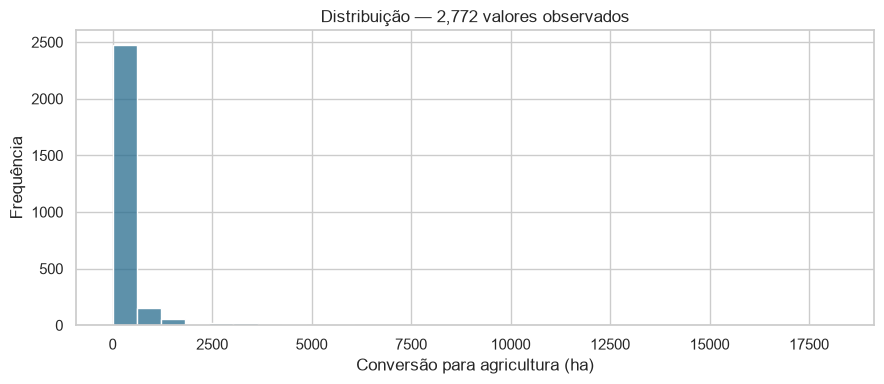

In [83]:
fig = histograma(painel, 'conversao_ha__agricultura', catalogo)
plt.show()
plt.close(fig)

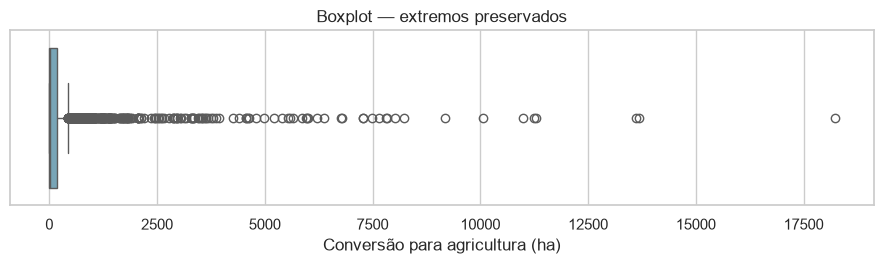

In [84]:
fig = boxplot(painel, 'conversao_ha__agricultura', catalogo)
plt.show()
plt.close(fig)

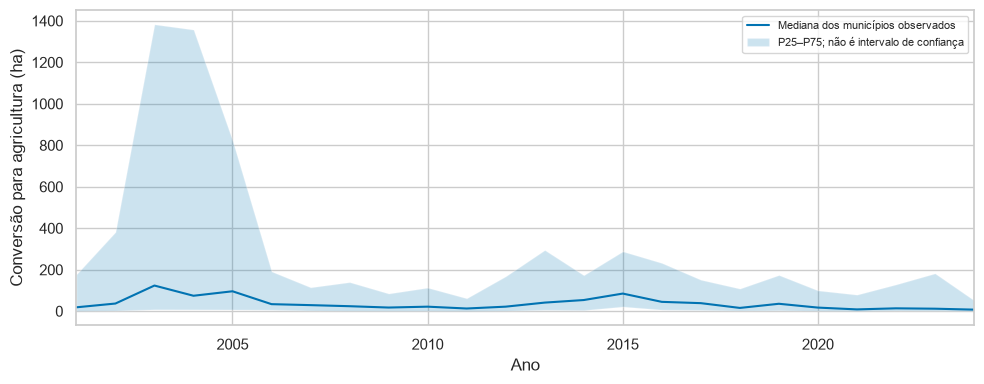

In [85]:
fig = serie_temporal(painel, 'conversao_ha__agricultura', catalogo)
plt.show()
plt.close(fig)

### Conversão para pastagem (ha)

Coluna: `conversao_ha__pastagem`.

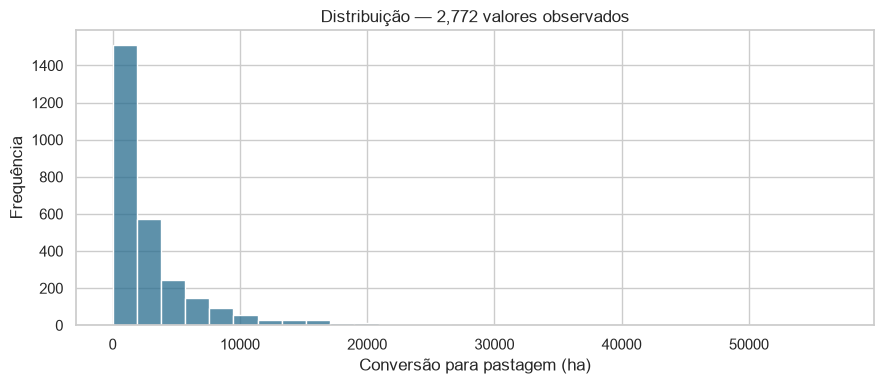

In [86]:
fig = histograma(painel, 'conversao_ha__pastagem', catalogo)
plt.show()
plt.close(fig)

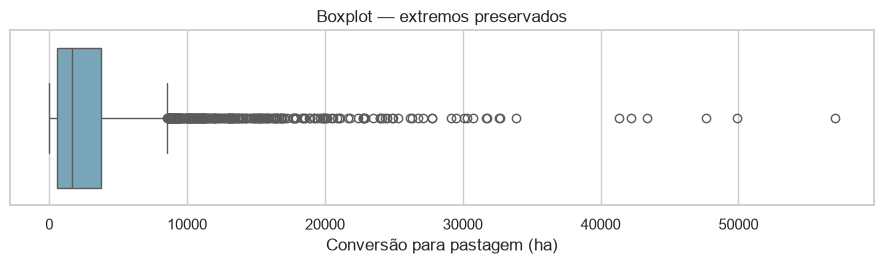

In [87]:
fig = boxplot(painel, 'conversao_ha__pastagem', catalogo)
plt.show()
plt.close(fig)

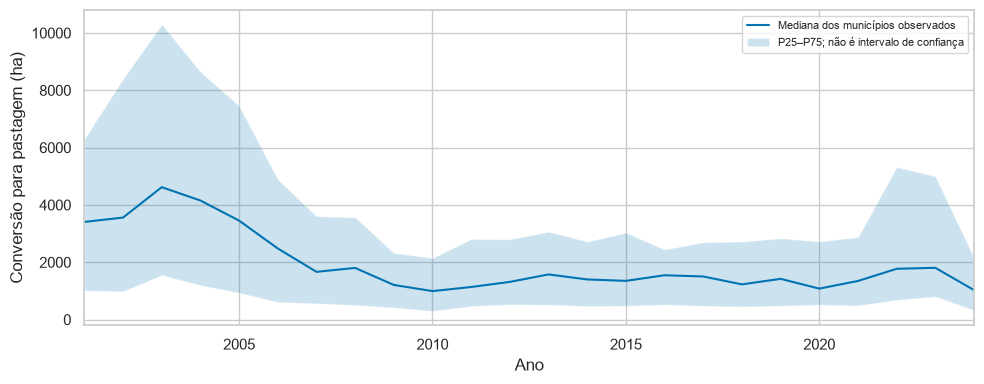

In [88]:
fig = serie_temporal(painel, 'conversao_ha__pastagem', catalogo)
plt.show()
plt.close(fig)

### Taxa de conversão para agricultura (proporção)

Coluna: `taxa_conversao__agricultura`.

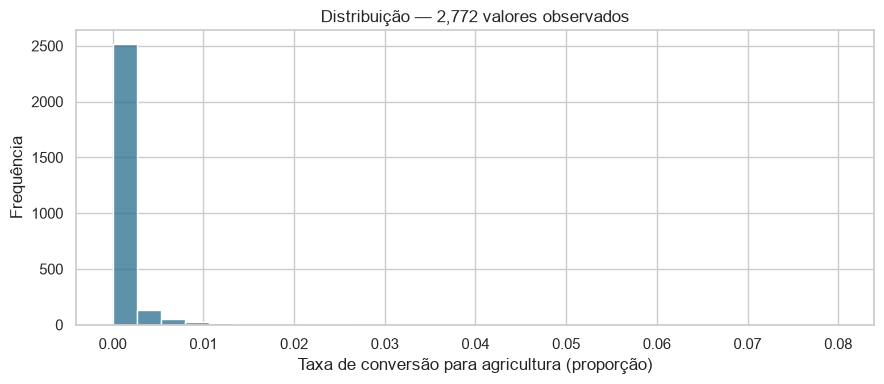

In [89]:
fig = histograma(painel, 'taxa_conversao__agricultura', catalogo)
plt.show()
plt.close(fig)

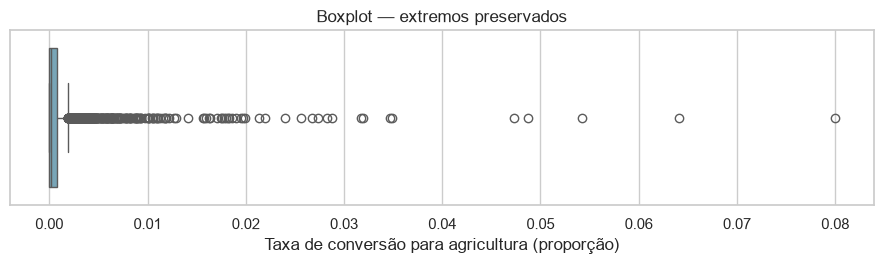

In [90]:
fig = boxplot(painel, 'taxa_conversao__agricultura', catalogo)
plt.show()
plt.close(fig)

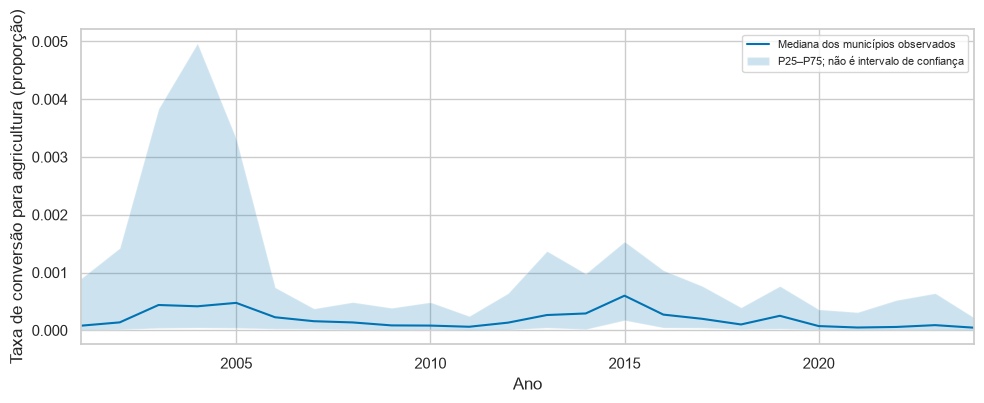

In [91]:
fig = serie_temporal(painel, 'taxa_conversao__agricultura', catalogo)
plt.show()
plt.close(fig)

### Taxa de conversão para pastagem (proporção)

Coluna: `taxa_conversao__pastagem`.

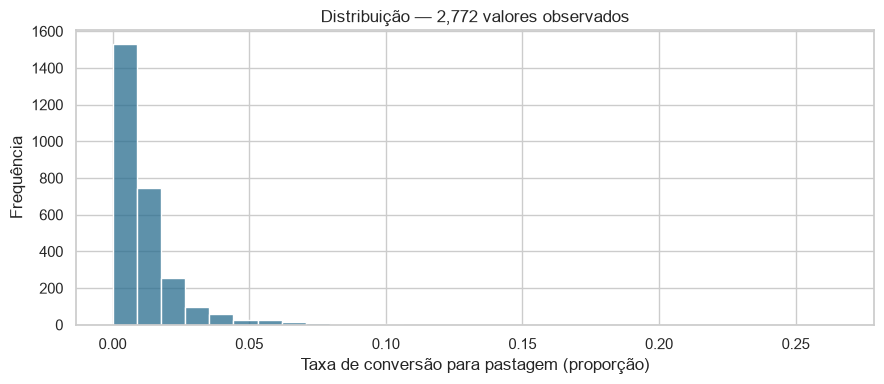

In [92]:
fig = histograma(painel, 'taxa_conversao__pastagem', catalogo)
plt.show()
plt.close(fig)

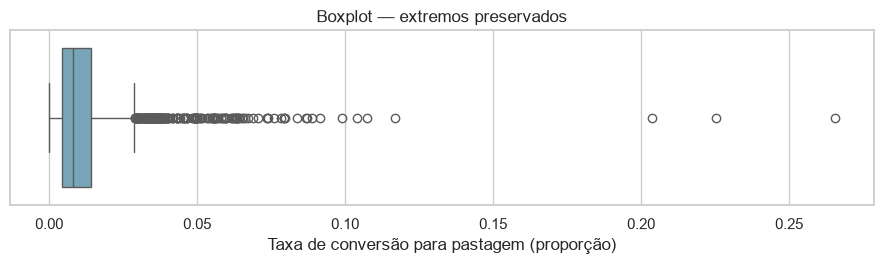

In [93]:
fig = boxplot(painel, 'taxa_conversao__pastagem', catalogo)
plt.show()
plt.close(fig)

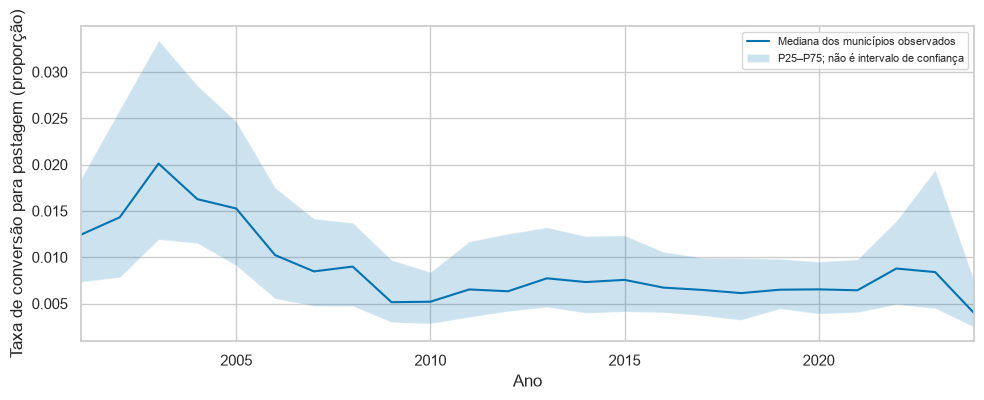

In [94]:
fig = serie_temporal(painel, 'taxa_conversao__pastagem', catalogo)
plt.show()
plt.close(fig)

### Preço real da soja (USD 2024/t)

Coluna: `preco_real_usd2024_media_anual__soja`.

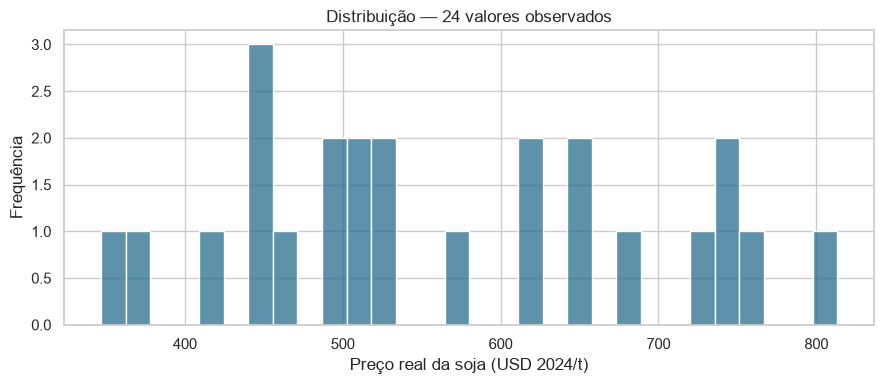

In [95]:
fig = histograma(painel, 'preco_real_usd2024_media_anual__soja', catalogo)
plt.show()
plt.close(fig)

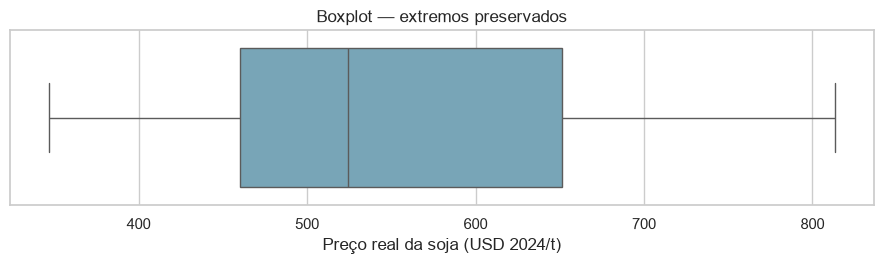

In [96]:
fig = boxplot(painel, 'preco_real_usd2024_media_anual__soja', catalogo)
plt.show()
plt.close(fig)

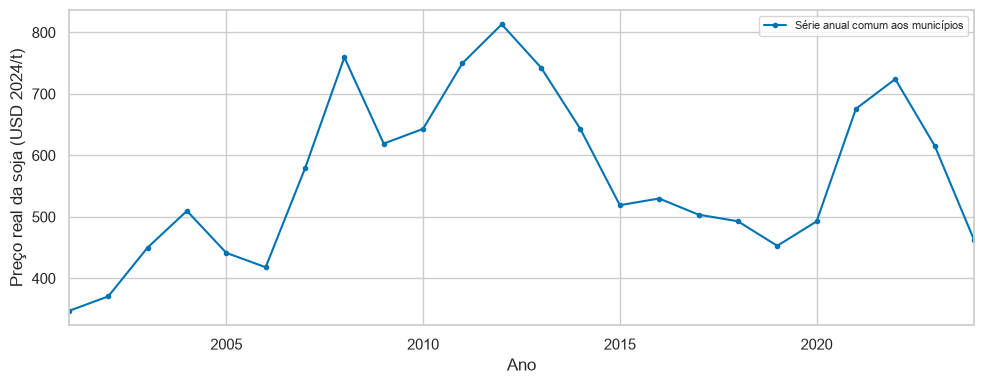

In [97]:
fig = serie_temporal(painel, 'preco_real_usd2024_media_anual__soja', catalogo)
plt.show()
plt.close(fig)

### Preço real do milho (USD 2024/t)

Coluna: `preco_real_usd2024_media_anual__milho`.

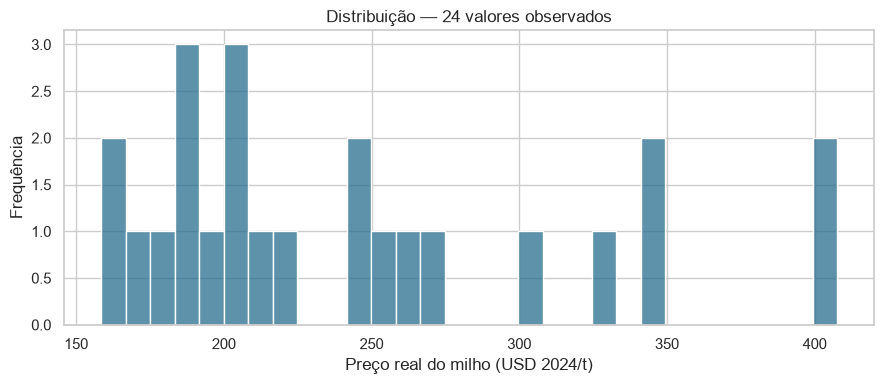

In [98]:
fig = histograma(painel, 'preco_real_usd2024_media_anual__milho', catalogo)
plt.show()
plt.close(fig)

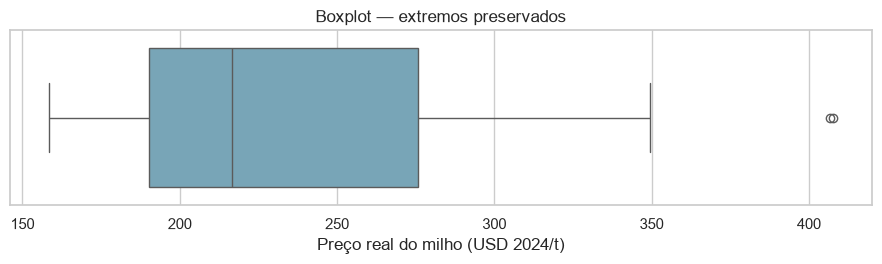

In [99]:
fig = boxplot(painel, 'preco_real_usd2024_media_anual__milho', catalogo)
plt.show()
plt.close(fig)

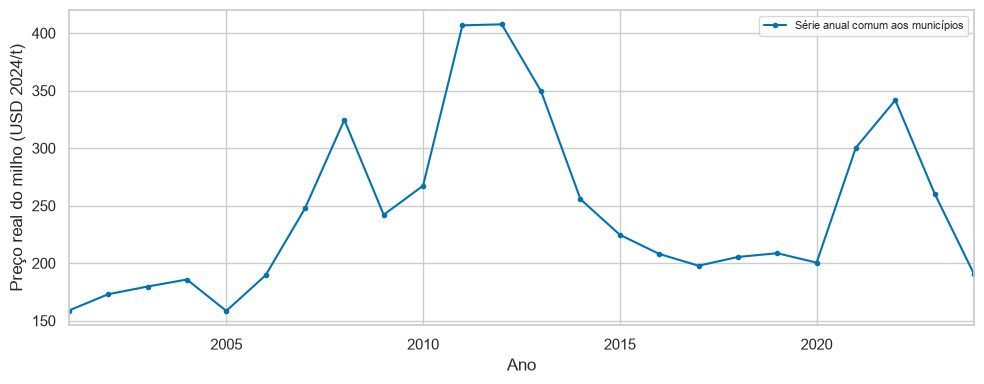

In [100]:
fig = serie_temporal(painel, 'preco_real_usd2024_media_anual__milho', catalogo)
plt.show()
plt.close(fig)

### Preço real da carne (USD 2024/kg)

Coluna: `preco_real_usd2024_media_anual__carne_bovina`.

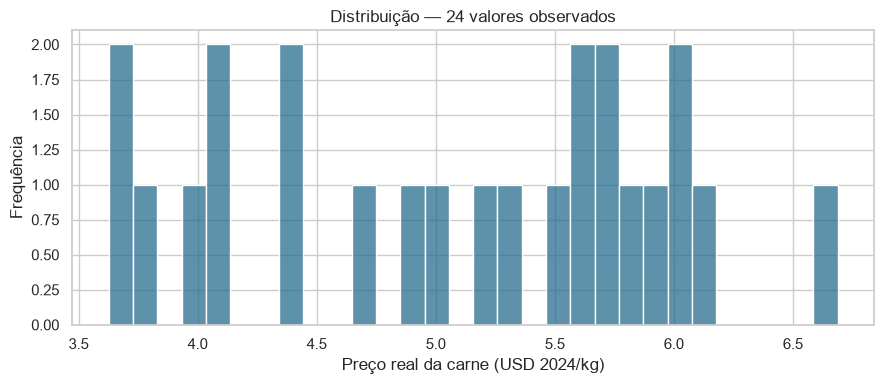

In [101]:
fig = histograma(painel, 'preco_real_usd2024_media_anual__carne_bovina', catalogo)
plt.show()
plt.close(fig)

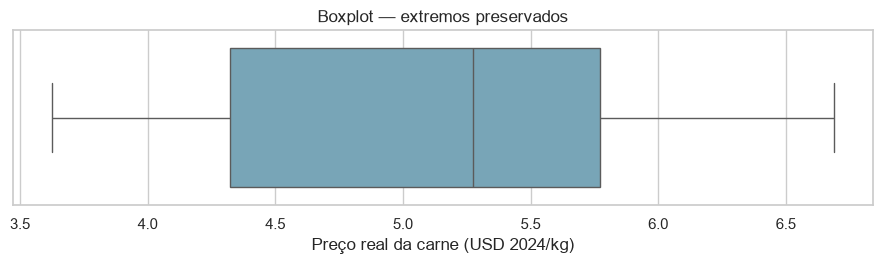

In [102]:
fig = boxplot(painel, 'preco_real_usd2024_media_anual__carne_bovina', catalogo)
plt.show()
plt.close(fig)

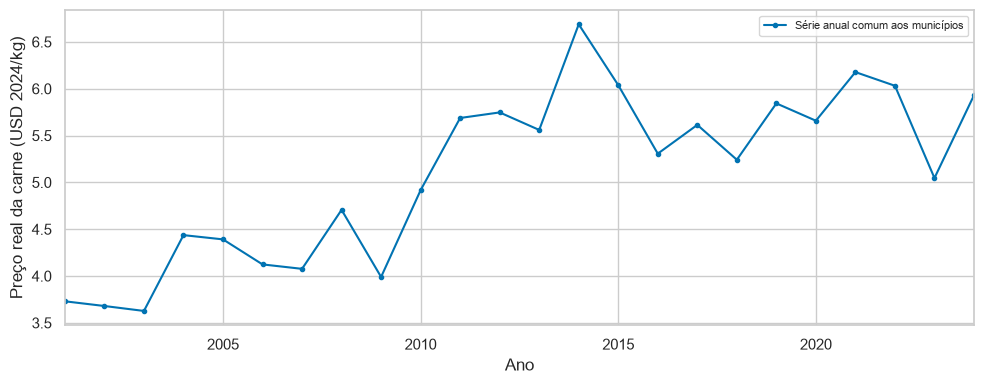

In [103]:
fig = serie_temporal(painel, 'preco_real_usd2024_media_anual__carne_bovina', catalogo)
plt.show()
plt.close(fig)

### Rendimento observado da soja (kg/ha)

Coluna: `rendimento_medio_kg_ha__Soja (em grão)`.

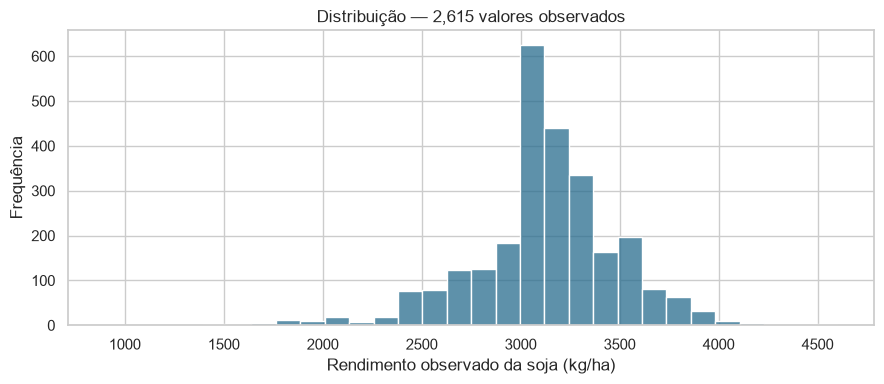

In [104]:
fig = histograma(painel, 'rendimento_medio_kg_ha__Soja (em grão)', catalogo)
plt.show()
plt.close(fig)

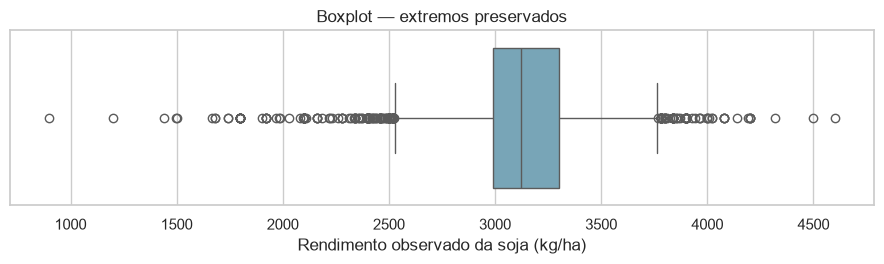

In [105]:
fig = boxplot(painel, 'rendimento_medio_kg_ha__Soja (em grão)', catalogo)
plt.show()
plt.close(fig)

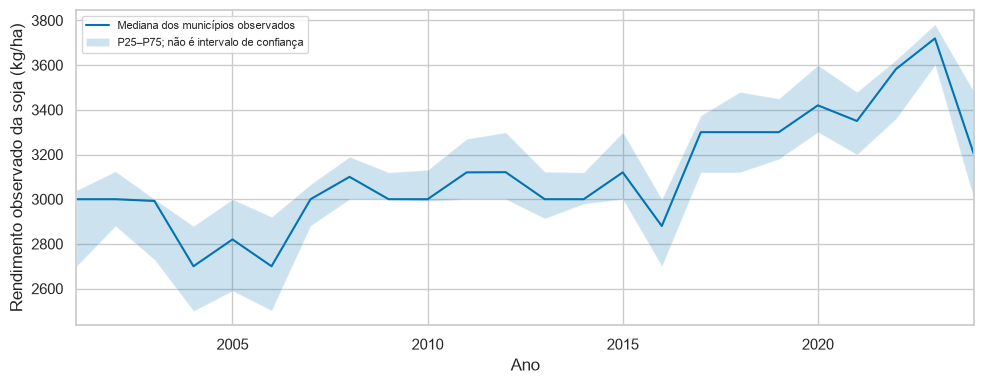

In [106]:
fig = serie_temporal(painel, 'rendimento_medio_kg_ha__Soja (em grão)', catalogo)
plt.show()
plt.close(fig)

### Rendimento observado do milho (kg/ha)

Coluna: `rendimento_medio_kg_ha__Milho (em grão)`.

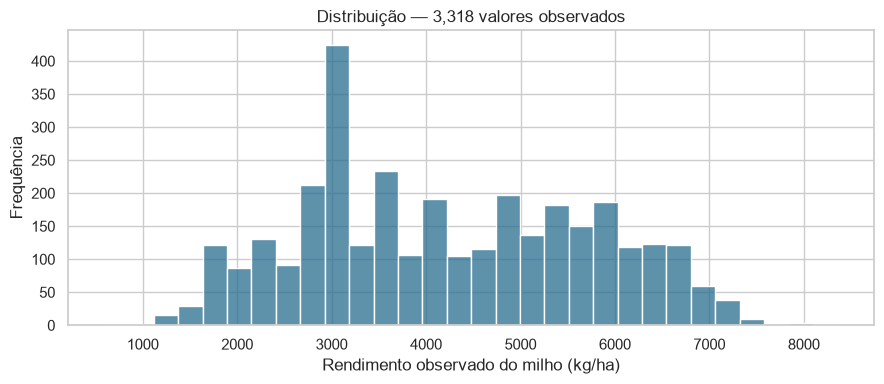

In [107]:
fig = histograma(painel, 'rendimento_medio_kg_ha__Milho (em grão)', catalogo)
plt.show()
plt.close(fig)

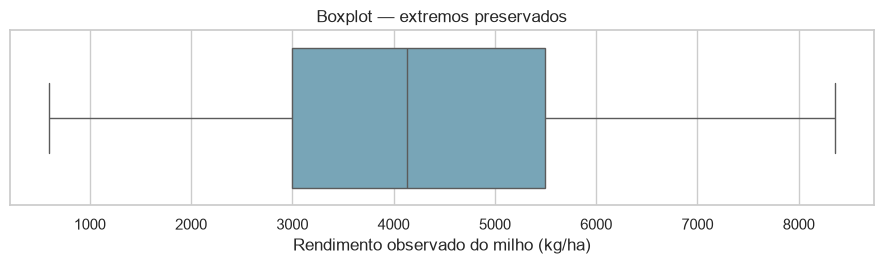

In [108]:
fig = boxplot(painel, 'rendimento_medio_kg_ha__Milho (em grão)', catalogo)
plt.show()
plt.close(fig)

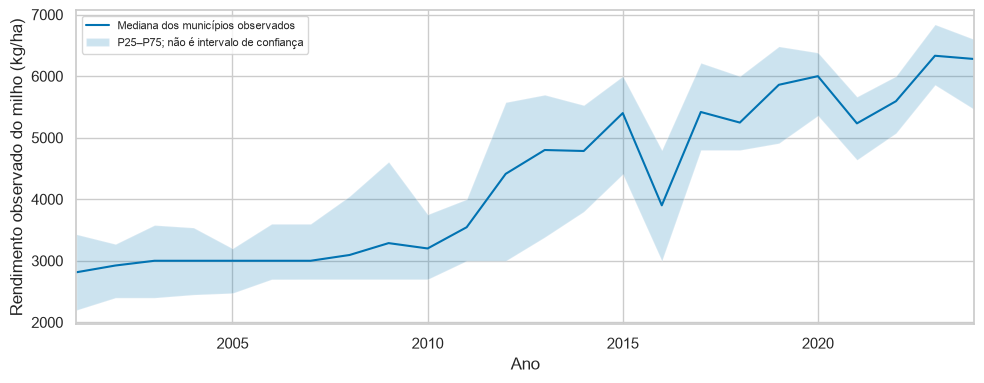

In [109]:
fig = serie_temporal(painel, 'rendimento_medio_kg_ha__Milho (em grão)', catalogo)
plt.show()
plt.close(fig)

### Rebanho bovino (cabeças)

Coluna: `efetivo_bovino`.

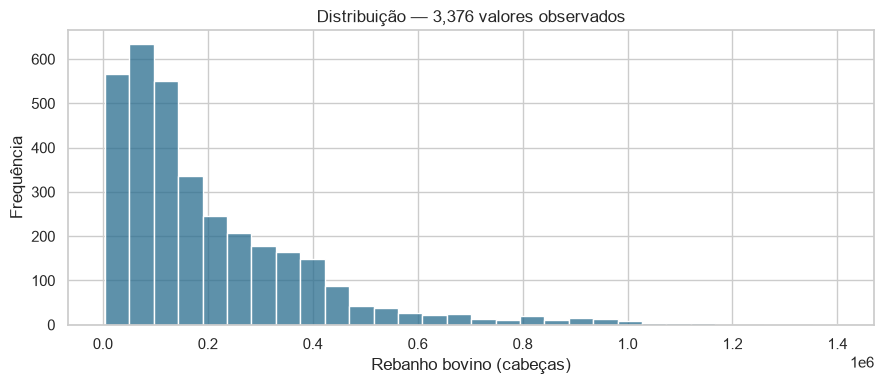

In [110]:
fig = histograma(painel, 'efetivo_bovino', catalogo)
plt.show()
plt.close(fig)

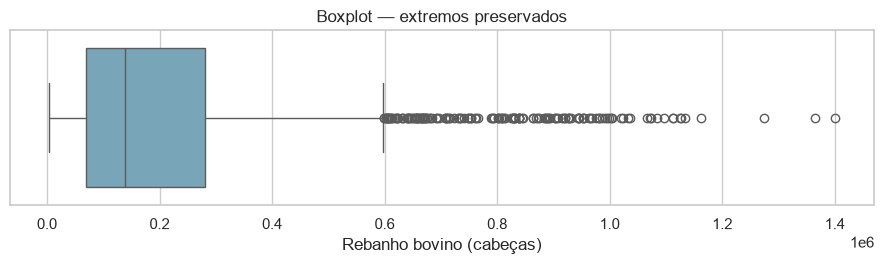

In [111]:
fig = boxplot(painel, 'efetivo_bovino', catalogo)
plt.show()
plt.close(fig)

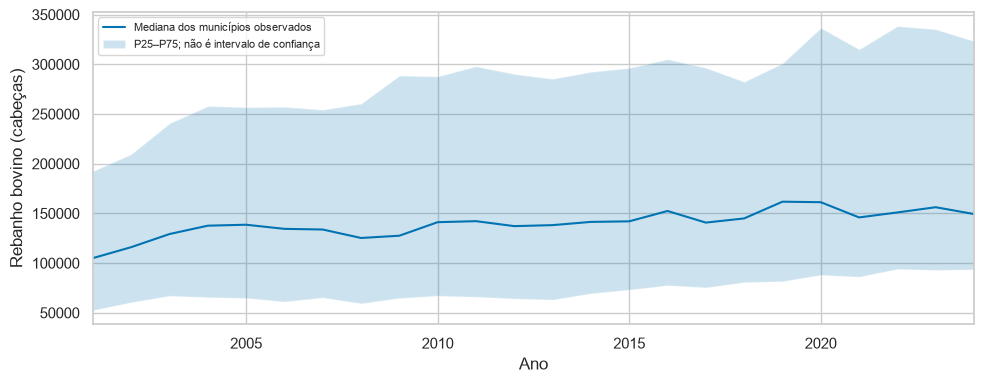

In [112]:
fig = serie_temporal(painel, 'efetivo_bovino', catalogo)
plt.show()
plt.close(fig)

### Lotação aparente (cabeças/ha)

Coluna: `lotacao_cabecas_ha`.

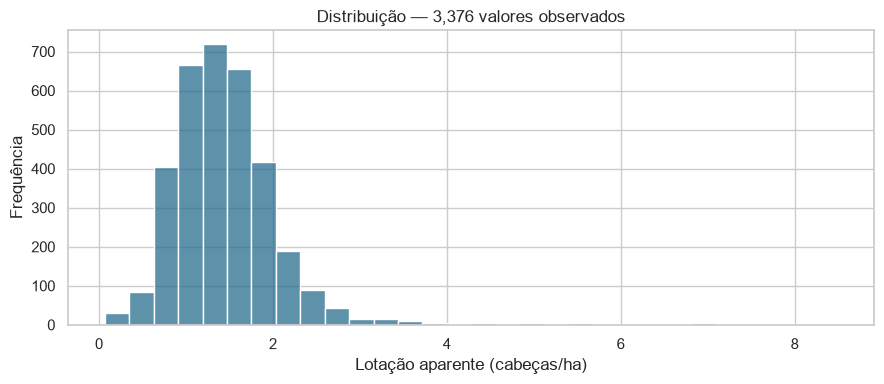

In [113]:
fig = histograma(painel, 'lotacao_cabecas_ha', catalogo)
plt.show()
plt.close(fig)

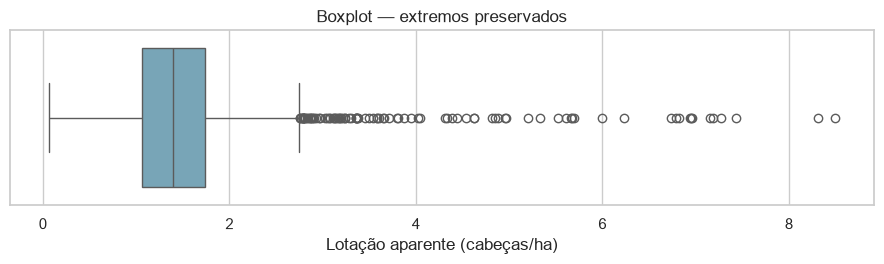

In [114]:
fig = boxplot(painel, 'lotacao_cabecas_ha', catalogo)
plt.show()
plt.close(fig)

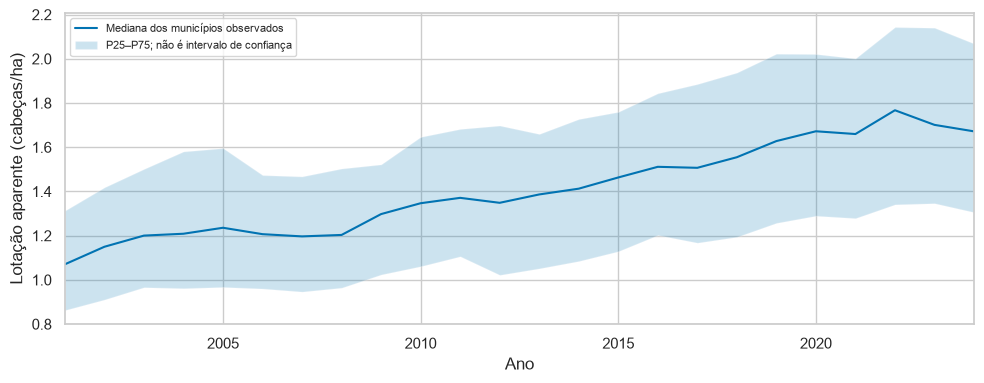

In [115]:
fig = serie_temporal(painel, 'lotacao_cabecas_ha', catalogo)
plt.show()
plt.close(fig)

### Chuva anual (mm)

Coluna: `precip_mm_anual`.

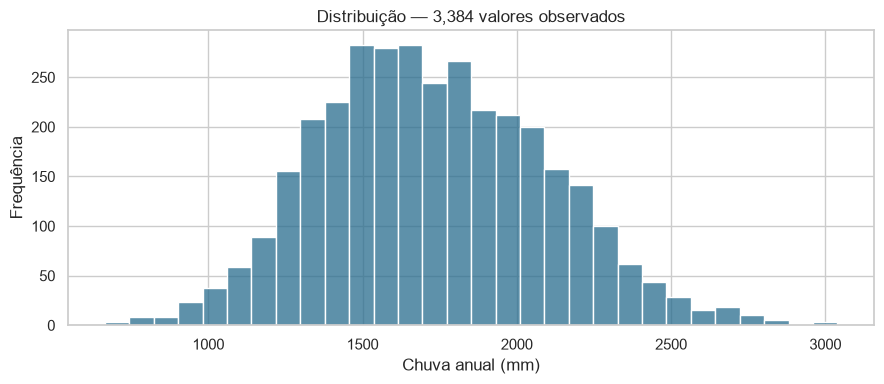

In [116]:
fig = histograma(painel, 'precip_mm_anual', catalogo)
plt.show()
plt.close(fig)

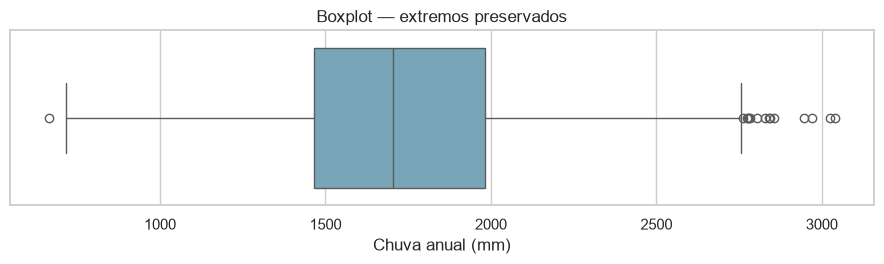

In [117]:
fig = boxplot(painel, 'precip_mm_anual', catalogo)
plt.show()
plt.close(fig)

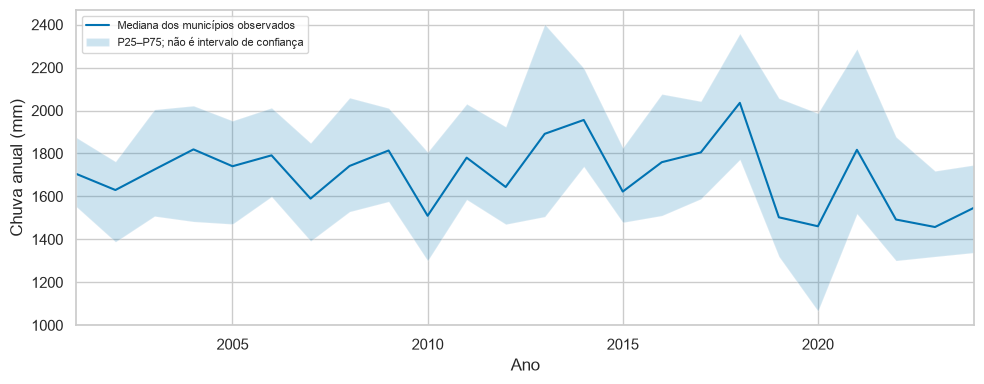

In [118]:
fig = serie_temporal(painel, 'precip_mm_anual', catalogo)
plt.show()
plt.close(fig)

### Anomalia padronizada da chuva (ref. 1981–2000)

Coluna: `precip_zscore_1981_2000`.

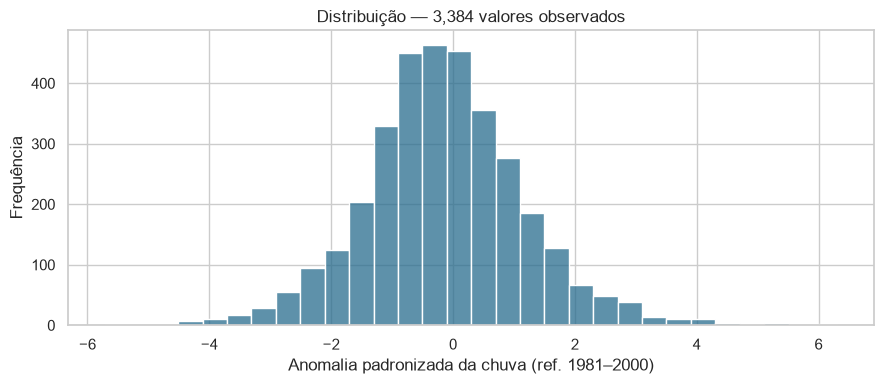

In [119]:
fig = histograma(painel, 'precip_zscore_1981_2000', catalogo)
plt.show()
plt.close(fig)

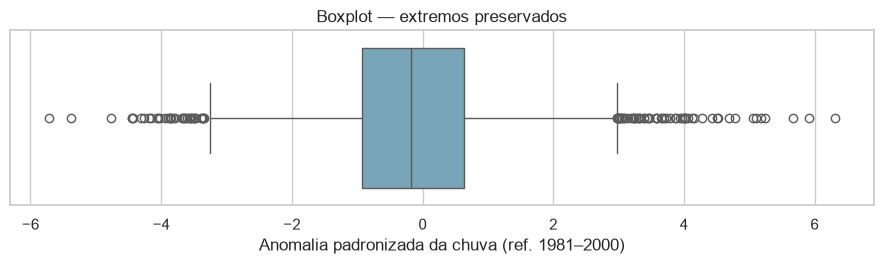

In [120]:
fig = boxplot(painel, 'precip_zscore_1981_2000', catalogo)
plt.show()
plt.close(fig)

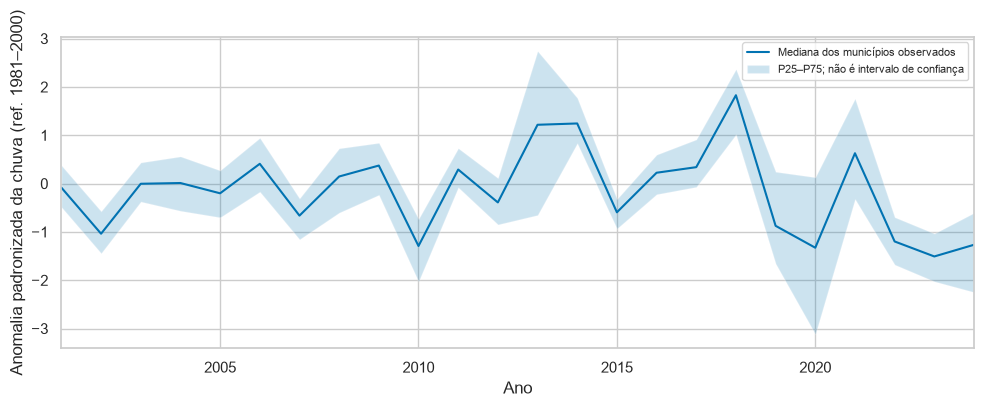

In [121]:
fig = serie_temporal(painel, 'precip_zscore_1981_2000', catalogo)
plt.show()
plt.close(fig)

### Autos de desmatamento — município informado (contagem)

Coluna: `n_autos_desmatamento__ibama_informada`.

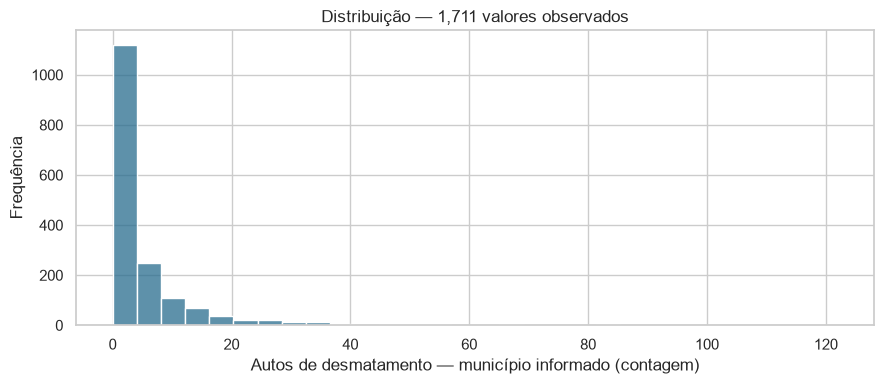

In [122]:
fig = histograma(painel, 'n_autos_desmatamento__ibama_informada', catalogo)
plt.show()
plt.close(fig)

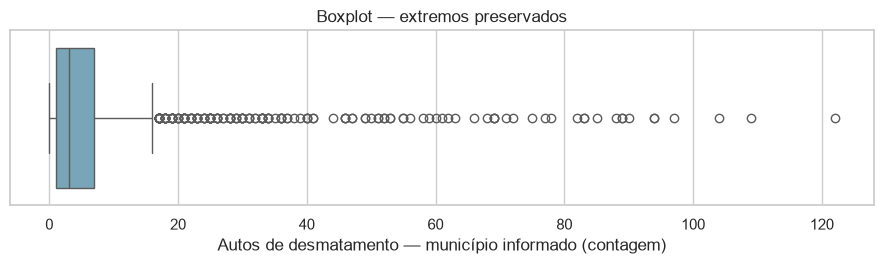

In [123]:
fig = boxplot(painel, 'n_autos_desmatamento__ibama_informada', catalogo)
plt.show()
plt.close(fig)

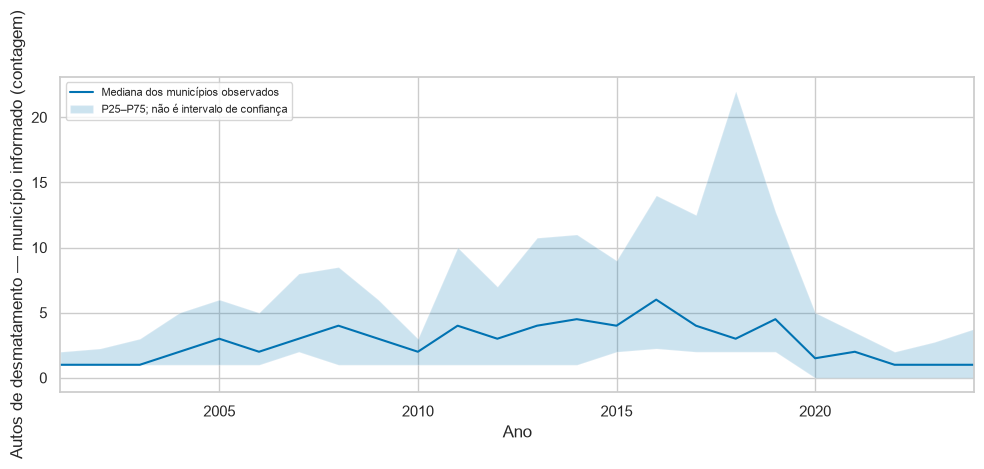

In [124]:
fig = serie_temporal(painel, 'n_autos_desmatamento__ibama_informada', catalogo)
plt.show()
plt.close(fig)

### Multas observadas de desmatamento (R$ dez. 2024)

Coluna: `multas_desmatamento_reais_observadas__ibama_informada`.

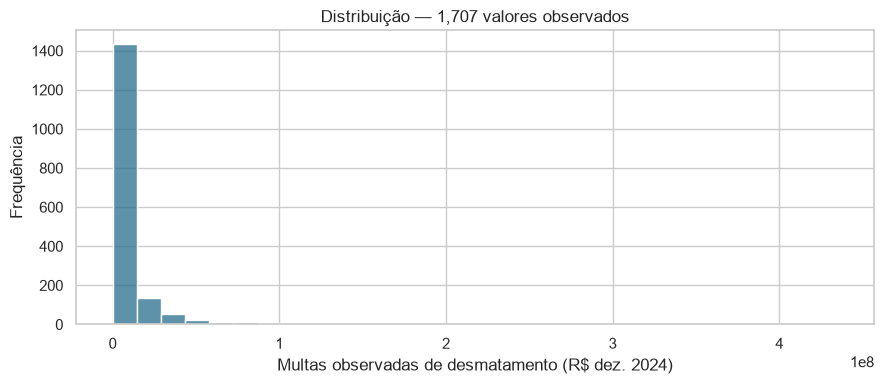

In [125]:
fig = histograma(painel, 'multas_desmatamento_reais_observadas__ibama_informada', catalogo)
plt.show()
plt.close(fig)

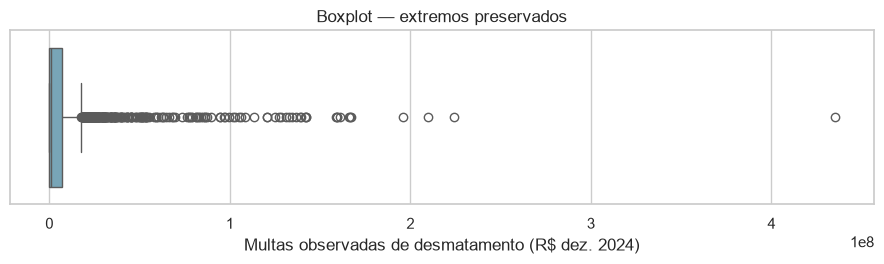

In [126]:
fig = boxplot(painel, 'multas_desmatamento_reais_observadas__ibama_informada', catalogo)
plt.show()
plt.close(fig)

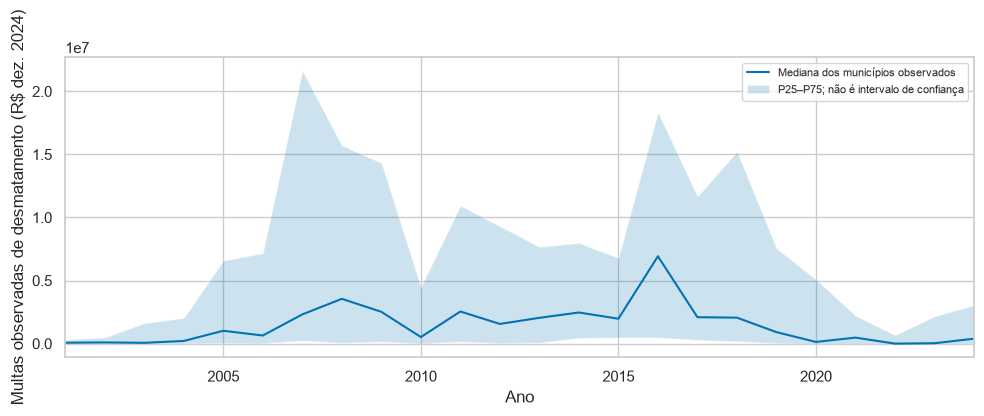

In [127]:
fig = serie_temporal(painel, 'multas_desmatamento_reais_observadas__ibama_informada', catalogo)
plt.show()
plt.close(fig)

### Elevação média da superfície (m)

Coluna: `elevation_mean_m`.

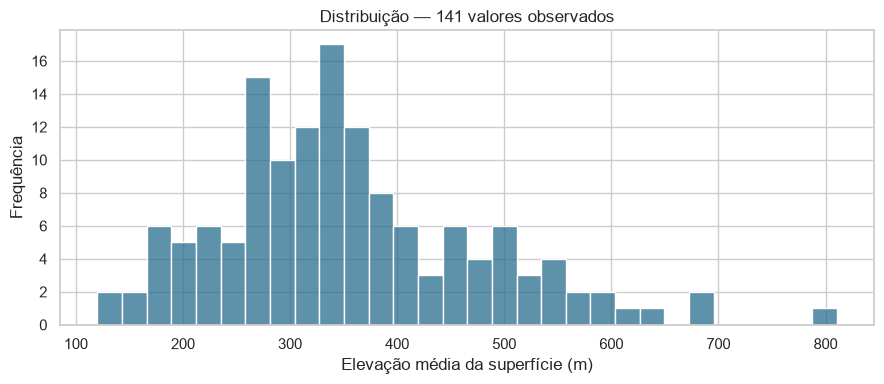

In [128]:
fig = histograma(painel, 'elevation_mean_m', catalogo)
plt.show()
plt.close(fig)

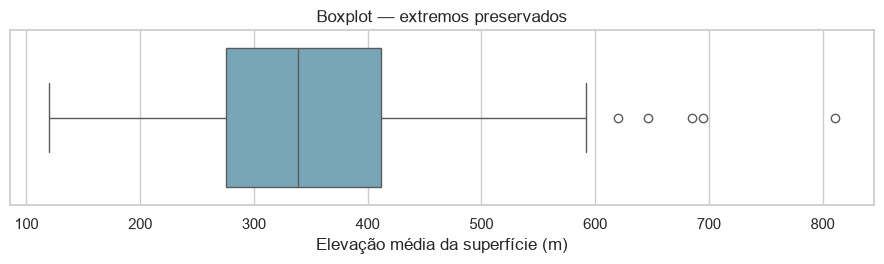

In [129]:
fig = boxplot(painel, 'elevation_mean_m', catalogo)
plt.show()
plt.close(fig)

## 8. Comparações por ano, município e geografia

Os resumos municipais abaixo excluem preços globais e atributos fixos para não repetir estatísticas sem variação temporal. As frações de bioma são mantidas como medidas contínuas. Para uma comparação descritiva adicional, o rótulo de 80% identifica municípios com essa predominância; os demais são mistos. A conversão pertence ao município inteiro, não à parcela do bioma.

In [130]:
MUNICIPAIS = catalogo.loc[catalogo.coluna_painel.isin(PRINCIPAIS) & catalogo.unidade_observacao.eq("município–ano"), "coluna_painel"].tolist()

In [131]:
resumo_anos = resumo_agrupado(painel, MUNICIPAIS, "ano")

In [132]:
display(resumo_anos)

,ano,variavel,n_validos,media,desvio_padrao,minimo,p25,mediana,p75,maximo
0,2001,conversao_ha__agricultura,117,535.4618,"1,582.7291",0.0000,1.1449,18.5637,177.4417,"11,256.2296"
1,2001,conversao_ha__pastagem,117,"4,534.6833","4,499.0194",91.8108,"1,018.0372","3,407.4880","6,299.9269","21,078.7807"
2,2001,efetivo_bovino,139,"143,320.9712","135,721.7678","4,115.0000","52,731.5000","105,000.0000","192,539.5000","740,776.0000"
3,2001,lotacao_cabecas_ha,139,1.0767,0.3962,0.0693,0.8631,1.0704,1.3133,2.4192
4,2001,multas_desmatamento_reais_observadas__ibama_informada,14,"307,673.6221","602,610.7937",520.4706,"18,629.9259","72,565.6110","305,240.4799","2,250,158.6239"
5,2001,n_autos_desmatamento__ibama_informada,14,1.7143,1.3828,1.0000,1.0000,1.0000,2.0000,6.0000
6,2001,precip_mm_anual,141,"1,734.9991",269.4250,"1,263.4889","1,551.7179","1,704.5949","1,873.8012","2,521.5794"
7,2001,precip_zscore_1981_2000,141,-0.0406,0.6925,-1.7440,-0.4868,-0.0843,0.3759,2.1940
8,2001,rendimento_medio_kg_ha__Milho (em grão),138,"2,878.1812",951.2908,800.0000,"2,200.0000","2,813.0000","3,430.0000","6,000.0000"
9,2001,rendimento_medio_kg_ha__Soja (em grão),77,"2,840.1818",368.6428,"1,680.0000","2,700.0000","3,000.0000","3,040.0000","3,662.0000"


In [133]:
resumo_municipios = resumo_agrupado(painel, MUNICIPAIS, "codigo_ibge")

In [134]:
display(resumo_municipios.pivot(index="codigo_ibge", columns="variavel", values="media"))

variavel,conversao_ha__agricultura,conversao_ha__pastagem,efetivo_bovino,lotacao_cabecas_ha,multas_desmatamento_reais_observadas__ibama_informada,n_autos_desmatamento__ibama_informada,precip_mm_anual,precip_zscore_1981_2000,rendimento_medio_kg_ha__Milho (em grão),rendimento_medio_kg_ha__Soja (em grão),taxa_conversao__agricultura,taxa_conversao__pastagem
codigo_ibge,,,,,,,,,,,,
5100102,4.6389,758.4944,"45,879.9167",1.7059,"946,931.4114",1.1429,"1,193.9622",-0.6217,"1,863.3684",NaN,0.0001,0.0136
5100201,50.7041,"4,027.5343","387,507.5417",1.3122,"714,592.7860",1.5833,"1,699.2677",0.0215,"4,611.4583","3,056.1250",0.0002,0.0122
5100250,9.8391,"2,419.0401","756,170.5417",1.8312,"8,774,947.0423",9.2273,"2,220.7591",0.0925,"3,992.6667","3,194.9500",0.0000,0.0056
5100300,66.1275,"2,849.9663","169,019.0833",0.8105,"112,005.0909",1.9286,"1,545.0842",-0.6698,"5,173.0833","2,920.1667",0.0002,0.0102
5100359,150.1559,"3,294.9358","69,998.0833",0.7244,"29,015,305.8044",5.0000,"1,767.6433",0.2007,"4,169.1250","3,125.9091",0.0013,0.0283
5100409,308.9649,"1,709.5908","74,821.5833",0.8947,"57,213.5061",1.0000,"1,514.6736",-0.5828,"5,429.0417","3,059.3333",0.0017,0.0097
5100508,15.1183,"1,354.2706","73,969.9167",1.2567,"20,284.7593",1.2500,"1,527.7898",-0.2648,"4,376.9583","3,046.8750",0.0001,0.0115
5100607,23.6347,146.1893,"21,157.2083",0.8443,"125,222.6467",1.6667,"1,530.7821",-0.7686,"6,115.2500","3,180.1250",0.0007,0.0044
5100805,16.8655,"7,728.8409","231,486.4583",1.3634,"21,831,837.8475",9.9500,"2,288.4321",0.3334,"3,539.1176","3,360.2000",0.0000,0.0041


In [135]:
FRACOES_BIOMAS = ["biome_amazonia_share_i", "biome_cerrado_share_i", "biome_pantanal_share_i"]

In [136]:
geografia = painel[["codigo_ibge"] + FRACOES_BIOMAS].drop_duplicates("codigo_ibge").copy()

In [137]:
display(geografia)

,codigo_ibge,biome_amazonia_share_i,biome_cerrado_share_i,biome_pantanal_share_i
0,5100102,0.0000,1.0000,0.0000
24,5100201,0.0002,0.9998,0.0000
48,5100250,1.0000,0.0000,0.0000
72,5100300,0.0000,1.0000,0.0000
96,5100359,0.7852,0.2148,0.0000
120,5100409,0.0000,1.0000,0.0000
144,5100508,0.1158,0.8842,0.0000
168,5100607,0.0000,1.0000,0.0000
192,5100805,1.0000,0.0000,0.0000
216,5101001,0.0000,1.0000,0.0000


In [138]:
geografia["grupo_bioma_80"] = geografia[FRACOES_BIOMAS].idxmax(axis=1).map({"biome_amazonia_share_i": "Amazônia ≥80%", "biome_cerrado_share_i": "Cerrado ≥80%", "biome_pantanal_share_i": "Pantanal ≥80%"}).where(geografia[FRACOES_BIOMAS].max(axis=1).ge(.8), "Misto (<80%)")
geografia.loc[geografia[FRACOES_BIOMAS].isna().any(axis=1), "grupo_bioma_80"] = "Sem cobertura"

In [139]:
display(geografia.groupby("grupo_bioma_80").size().rename("n_municipios").to_frame())

,n_municipios
grupo_bioma_80,
Amazônia ≥80%,62
Cerrado ≥80%,51
Misto (<80%),26
Pantanal ≥80%,2


In [140]:
painel_geografia = painel.merge(geografia[["codigo_ibge", "grupo_bioma_80"]], on="codigo_ibge", how="left", validate="many_to_one")

In [141]:
resumo_biomas = resumo_agrupado(painel_geografia, MUNICIPAIS, "grupo_bioma_80")

In [142]:
display(resumo_biomas)

,grupo_bioma_80,variavel,n_validos,media,desvio_padrao,minimo,p25,mediana,p75,maximo
0,Amazônia ≥80%,conversao_ha__agricultura,1028,394.6299,"1,347.6690",0.0000,1.3671,26.3164,241.2099,"18,222.2681"
1,Amazônia ≥80%,conversao_ha__pastagem,1028,"4,525.0038","6,485.0700",0.9532,533.3990,"1,898.6108","6,007.1764","56,983.2254"
2,Amazônia ≥80%,efetivo_bovino,1480,"244,697.8514","220,618.8754","7,174.0000","84,059.2500","170,402.5000","351,899.5000","1,134,427.0000"
3,Amazônia ≥80%,lotacao_cabecas_ha,1480,1.5098,0.6259,0.0693,1.1519,1.4827,1.7697,7.1560
4,Amazônia ≥80%,multas_desmatamento_reais_observadas__ibama_informada,938,"12,941,619.4795","28,935,416.6820",0.0000,"325,936.8708","2,617,466.0921","13,254,518.3318","435,045,235.2036"
5,Amazônia ≥80%,n_autos_desmatamento__ibama_informada,938,9.3198,15.7536,0.0000,1.0000,4.0000,10.0000,122.0000
6,Amazônia ≥80%,precip_mm_anual,1488,"1,904.9551",397.0453,760.0863,"1,640.4282","1,971.4393","2,181.4616","3,038.9872"
7,Amazônia ≥80%,precip_zscore_1981_2000,1488,0.0469,1.3669,-4.0668,-0.8224,-0.0799,0.8231,6.3088
8,Amazônia ≥80%,rendimento_medio_kg_ha__Milho (em grão),1467,"4,013.2311","1,416.0640","1,200.0000","3,000.0000","3,600.0000","5,100.0000","7,200.0000"
9,Amazônia ≥80%,rendimento_medio_kg_ha__Soja (em grão),1041,"3,174.8357",345.0600,"1,668.0000","3,000.0000","3,121.0000","3,360.0000","4,600.0000"


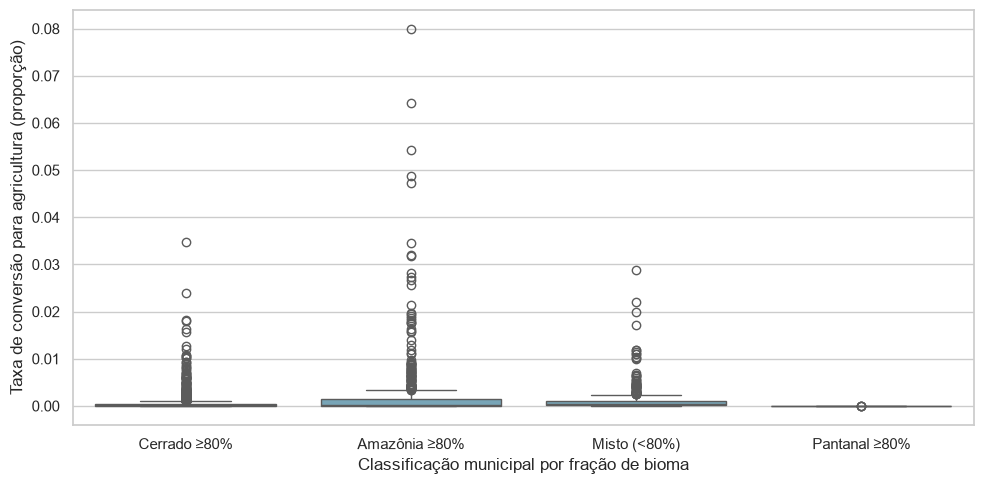

In [143]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=painel_geografia, x="grupo_bioma_80", y="taxa_conversao__agricultura", ax=ax, color="#6daac2")
ax.set(xlabel="Classificação municipal por fração de bioma", ylabel="Taxa de conversão para agricultura (proporção)")
fig.tight_layout()
plt.show()
plt.close(fig)

## 9. Conversão: cobertura e duas formas de resumir taxas

A soma de hectares abaixo cobre somente os municípios observados; não é um total estadual completo. A média simples de taxas dá o mesmo peso a cada município. A razão das somas usa a área nativa inicial como peso. Numerador e denominador usam exatamente a mesma amostra válida. Agricultura e pastagem permanecem separadas.

Também mostramos o subconjunto com Y observado nos 24 anos. Ele estabiliza a composição, mas pode selecionar municípios diferentes dos excluídos; não substitui automaticamente a amostra principal.

In [144]:
conversao_ano = resumo_y(painel)

In [145]:
display(conversao_ano)

,ano,destino,n_municipios_grade,n_validos,n_ausentes,n_zeros,conversao_observada_ha,nativa_inicial_mesma_amostra_ha,taxa_media_simples,taxa_razao_das_somas
0,2001,agricultura,141,117,24,21,"62,649.0257","49,392,613.7782",0.0018,0.0013
1,2001,pastagem,141,117,24,0,"530,557.9455","49,392,613.7782",0.0172,0.0107
2,2002,agricultura,141,116,25,13,"50,052.5407","46,768,652.5992",0.0015,0.0011
3,2002,pastagem,141,116,25,0,"686,537.1730","46,768,652.5992",0.0195,0.0147
4,2003,agricultura,141,116,25,11,"172,000.2510","45,916,936.8737",0.0047,0.0037
5,2003,pastagem,141,116,25,0,"879,328.2142","45,916,936.8737",0.0247,0.0192
6,2004,agricultura,141,115,26,14,"139,223.1957","43,730,182.7153",0.0044,0.0032
7,2004,pastagem,141,115,26,0,"803,803.7981","43,730,182.7153",0.0220,0.0184
8,2005,agricultura,141,115,26,11,"75,314.6209","42,461,107.9516",0.0026,0.0018
9,2005,pastagem,141,115,26,0,"649,605.4592","42,461,107.9516",0.0191,0.0153


In [146]:
conversao_balanceada = resumo_y(painel, apenas_balanceados=True)

In [147]:
display(conversao_balanceada)

,ano,destino,n_municipios_grade,n_validos,n_ausentes,n_zeros,conversao_observada_ha,nativa_inicial_mesma_amostra_ha,taxa_media_simples,taxa_razao_das_somas
0,2001,agricultura,95,95,0,15,"51,074.4005","31,651,212.1264",0.0019,0.0016
1,2001,pastagem,95,95,0,0,"338,419.3436","31,651,212.1264",0.0177,0.0107
2,2002,agricultura,95,95,0,13,"41,331.0320","31,259,755.3032",0.0016,0.0013
3,2002,pastagem,95,95,0,0,"433,899.8159","31,259,755.3032",0.0189,0.0139
4,2003,agricultura,95,95,0,10,"104,327.4762","30,740,639.6961",0.0043,0.0034
5,2003,pastagem,95,95,0,0,"543,749.3226","30,740,639.6961",0.0239,0.0177
6,2004,agricultura,95,95,0,12,"95,172.6587","30,058,637.4019",0.0042,0.0032
7,2004,pastagem,95,95,0,0,"510,264.8577","30,058,637.4019",0.0210,0.0170
8,2005,agricultura,95,95,0,11,"54,259.9904","29,471,648.1600",0.0026,0.0018
9,2005,pastagem,95,95,0,0,"421,859.0273","29,471,648.1600",0.0181,0.0143


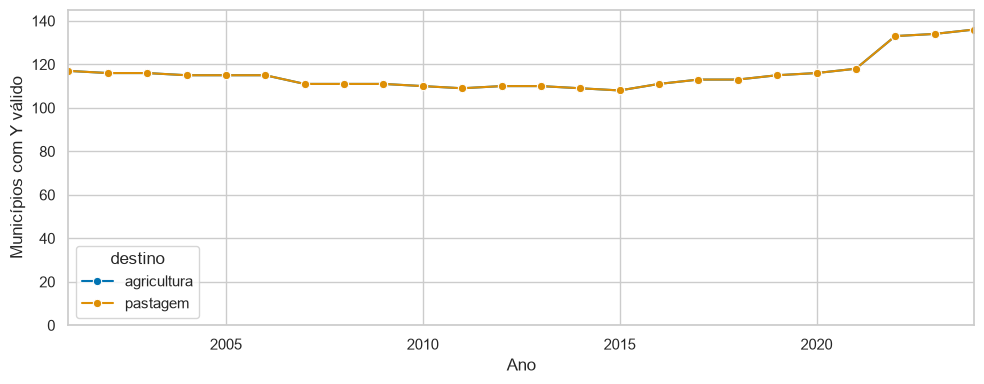

In [148]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=conversao_ano, x="ano", y="n_validos", hue="destino", marker="o", ax=ax)
ax.set(xlabel="Ano", ylabel="Municípios com Y válido", ylim=(0, 145), xlim=(2001, 2024))
fig.tight_layout()
plt.show()
plt.close(fig)

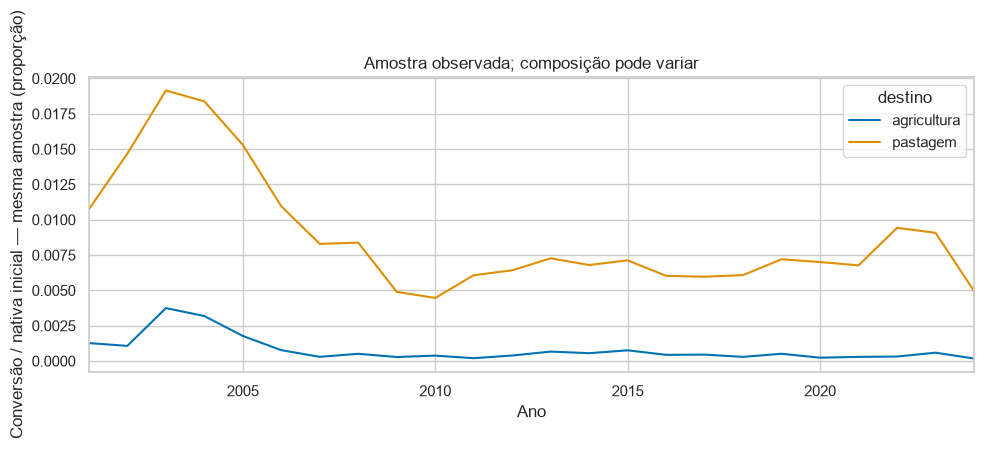

In [149]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=conversao_ano, x="ano", y="taxa_razao_das_somas", hue="destino", ax=ax)
ax.set(xlabel="Ano", ylabel="Conversão / nativa inicial — mesma amostra (proporção)", title="Amostra observada; composição pode variar", xlim=(2001, 2024))
fig.tight_layout()
plt.show()
plt.close(fig)

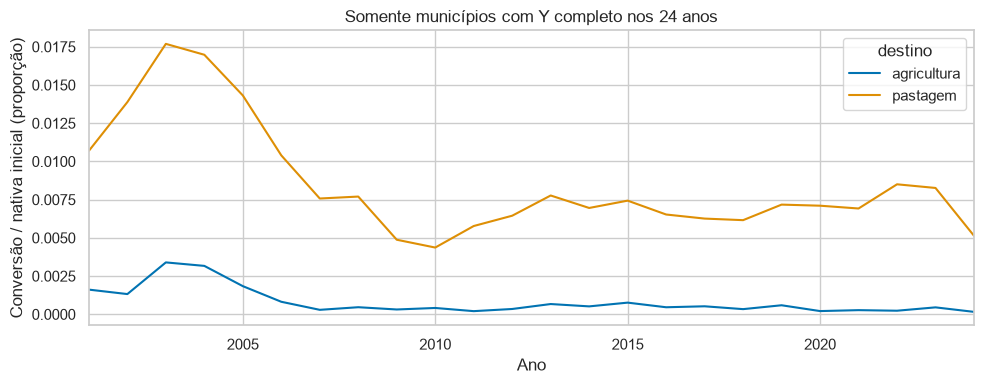

In [150]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=conversao_balanceada, x="ano", y="taxa_razao_das_somas", hue="destino", ax=ax)
ax.set(xlabel="Ano", ylabel="Conversão / nativa inicial (proporção)", title="Somente municípios com Y completo nos 24 anos", xlim=(2001, 2024))
fig.tight_layout()
plt.show()
plt.close(fig)

## 10. Variação do painel e associação descritiva

O desvio das médias municipais descreve diferenças entre municípios; o desvio de `x_it − média_i` descreve variação dentro deles. Em amostra incompleta, essas colunas não formam uma decomposição aditiva simples da variância. Atributos fixos têm variação interna nula; preços globais variam somente no tempo.

As correlações abaixo usam uma amostra comum e apenas medidas municipais selecionadas. Informamos sua cobertura. A segunda matriz retira a média de cada município nessa amostra; não retira efeitos de ano e não representa identificação causal. Não calculamos p-valores supondo independência das linhas.

In [151]:
variacao = variacao_painel(painel, descritiva.variavel.tolist())

In [152]:
display(variacao)

,variavel,n_observacoes,n_municipios,dp_total,dp_medias_municipais,dp_desvios_da_media_municipal,municipios_com_variacao_temporal
0,conversao_ha__agricultura,2772,137,"1,015.3823",640.3280,857.7074,134
1,conversao_ha__pastagem,2772,137,"4,832.1764","3,976.3583","3,080.0788",134
2,taxa_conversao__agricultura,2772,137,0.0038,0.0019,0.0032,134
3,taxa_conversao__pastagem,2772,137,0.0143,0.0079,0.0120,134
4,y_nativa_inicial_ha,3384,141,"495,642.2565","496,418.9655","30,081.1037",141
5,preco_nominal_media_anual__carne_bovina,3384,141,1.1408,0.0000,1.1408,141
6,preco_nominal_media_anual__milho,3384,141,65.3916,0.0000,65.3916,141
7,preco_nominal_media_anual__soja,3384,141,126.3958,0.0000,126.3958,141
8,preco_real_usd2024_media_anual__carne_bovina,3384,141,0.8832,0.0000,0.8832,141
9,preco_real_usd2024_media_anual__milho,3384,141,72.4326,0.0000,72.4326,141


In [153]:
COLUNAS_CORRELACAO = ["taxa_conversao__agricultura", "taxa_conversao__pastagem", "efetivo_bovino", "lotacao_cabecas_ha", "precip_mm_anual", "rendimento_medio_kg_ha__Soja (em grão)", "rendimento_medio_kg_ha__Milho (em grão)"]

In [154]:
amostra_correlacao = painel[["codigo_ibge", "ano"] + COLUNAS_CORRELACAO].dropna(subset=COLUNAS_CORRELACAO).copy()

In [155]:
display(pd.DataFrame({"n_pares": [len(amostra_correlacao)], "n_municipios": [amostra_correlacao.codigo_ibge.nunique()], "n_anos": [amostra_correlacao.ano.nunique()], "ano_min": [amostra_correlacao.ano.min()], "ano_max": [amostra_correlacao.ano.max()]}))

,n_pares,n_municipios,n_anos,ano_min,ano_max
0,2123,130,24,2001,2024


In [156]:
display(amostra_correlacao.groupby("ano").size().rename("n_pares_completos").to_frame())

,n_pares_completos
ano,
2001,65
2002,69
2003,79
2004,85
2005,89
2006,85
2007,75
2008,75
2009,74


In [157]:
correlacao_niveis = amostra_correlacao[COLUNAS_CORRELACAO].corr()

In [158]:
display(correlacao_niveis)

,taxa_conversao__agricultura,taxa_conversao__pastagem,efetivo_bovino,lotacao_cabecas_ha,precip_mm_anual,rendimento_medio_kg_ha__Soja (em grão),rendimento_medio_kg_ha__Milho (em grão)
taxa_conversao__agricultura,1.0000,0.2314,-0.2126,-0.0438,0.1289,-0.0749,-0.1369
taxa_conversao__pastagem,0.2314,1.0000,-0.0178,-0.1605,0.0375,-0.0860,-0.2398
efetivo_bovino,-0.2126,-0.0178,1.0000,0.1014,-0.0145,0.1391,0.0528
lotacao_cabecas_ha,-0.0438,-0.1605,0.1014,1.0000,0.0670,0.2369,0.2661
precip_mm_anual,0.1289,0.0375,-0.0145,0.0670,1.0000,-0.0366,-0.0604
rendimento_medio_kg_ha__Soja (em grão),-0.0749,-0.0860,0.1391,0.2369,-0.0366,1.0000,0.5472
rendimento_medio_kg_ha__Milho (em grão),-0.1369,-0.2398,0.0528,0.2661,-0.0604,0.5472,1.0000


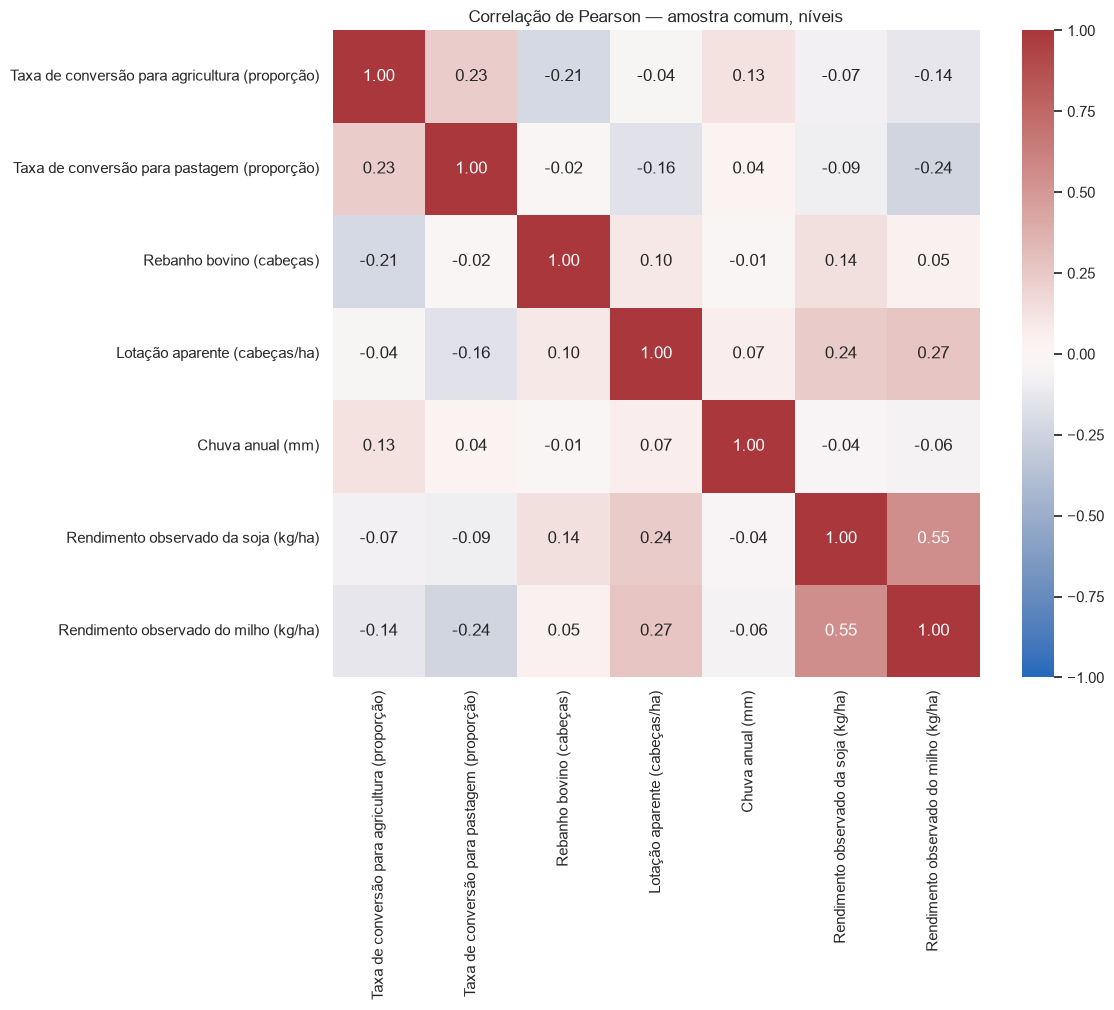

In [159]:
fig = grafico_correlacao(correlacao_niveis, "Correlação de Pearson — amostra comum, níveis")
plt.show()
plt.close(fig)

In [160]:
desvios_municipais = amostra_correlacao[COLUNAS_CORRELACAO] - amostra_correlacao.groupby("codigo_ibge")[COLUNAS_CORRELACAO].transform("mean")

In [161]:
correlacao_interna = desvios_municipais.corr()

In [162]:
display(correlacao_interna)

,taxa_conversao__agricultura,taxa_conversao__pastagem,efetivo_bovino,lotacao_cabecas_ha,precip_mm_anual,rendimento_medio_kg_ha__Soja (em grão),rendimento_medio_kg_ha__Milho (em grão)
taxa_conversao__agricultura,1.0000,0.3184,-0.0377,-0.2476,-0.0261,-0.1128,-0.2032
taxa_conversao__pastagem,0.3184,1.0000,-0.0933,-0.1826,-0.0570,-0.1338,-0.2338
efetivo_bovino,-0.0377,-0.0933,1.0000,0.3722,-0.1332,0.3506,0.3293
lotacao_cabecas_ha,-0.2476,-0.1826,0.3722,1.0000,-0.0019,0.2868,0.4122
precip_mm_anual,-0.0261,-0.0570,-0.1332,-0.0019,1.0000,-0.2106,-0.1046
rendimento_medio_kg_ha__Soja (em grão),-0.1128,-0.1338,0.3506,0.2868,-0.2106,1.0000,0.5656
rendimento_medio_kg_ha__Milho (em grão),-0.2032,-0.2338,0.3293,0.4122,-0.1046,0.5656,1.0000


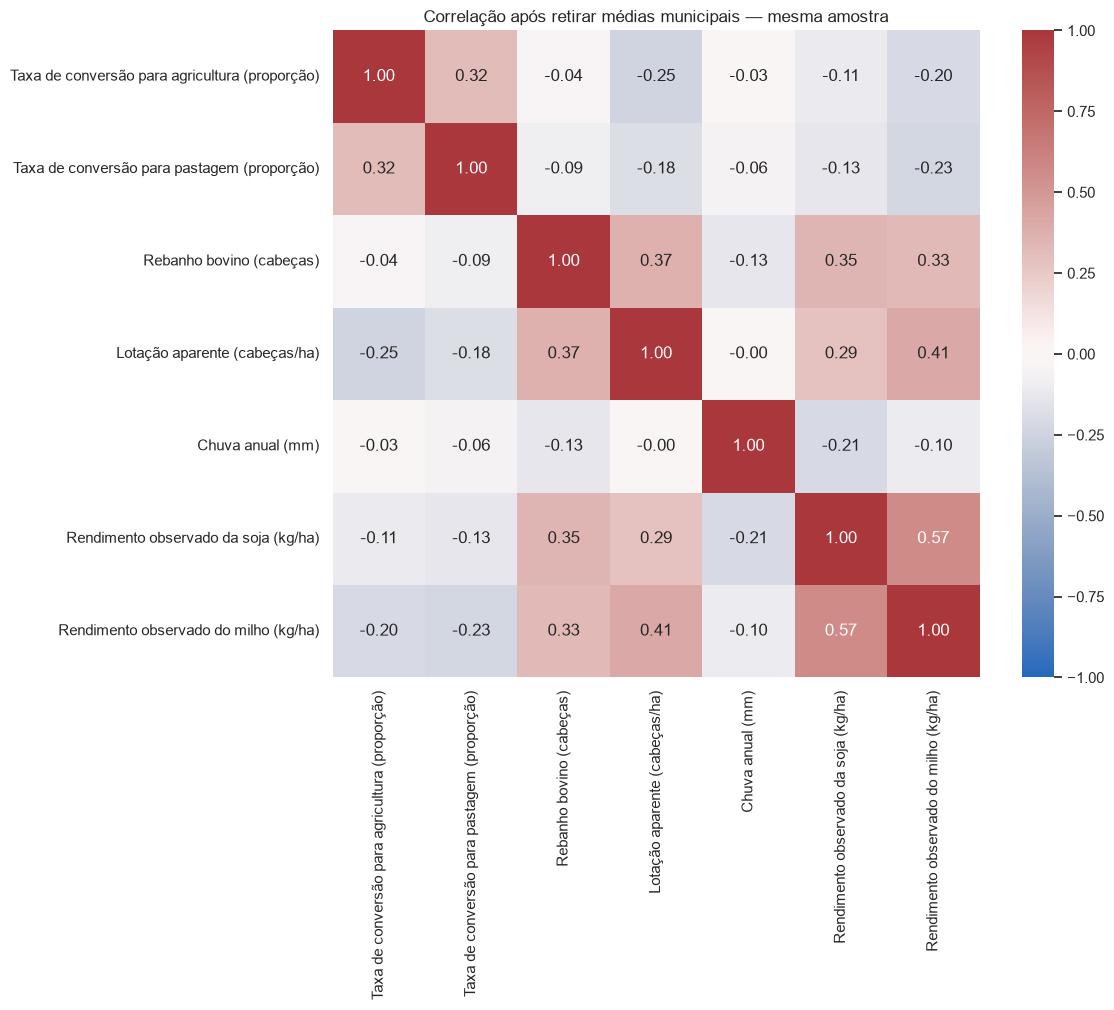

In [163]:
fig = grafico_correlacao(correlacao_interna, "Correlação após retirar médias municipais — mesma amostra")
plt.show()
plt.close(fig)

## 11. Cobertura conjunta e seleção da amostra

Estes conjuntos são diagnósticos de disponibilidade, não especificações econométricas escolhidas. Evitamos excluir linhas por ausência em qualquer uma das 296 colunas, pois elas incluem alternativas e diagnósticos. A comparação entre pares com e sem Y ajuda a descrever seleção; não identifica a causa das ausências.

In [164]:
CENARIOS = {
    "Y nos dois destinos": ["taxa_conversao__agricultura", "taxa_conversao__pastagem"],
    "Y + chuva": ["taxa_conversao__agricultura", "taxa_conversao__pastagem", "precip_mm_anual"],
    "Y + chuva + rendimentos + rebanho/lotação": COLUNAS_CORRELACAO,
    "Y + chuva + autos desmatamento informados": ["taxa_conversao__agricultura", "taxa_conversao__pastagem", "precip_mm_anual", "n_autos_desmatamento__ibama_informada"],
    "Y + exposição PAM soja": ["taxa_conversao__agricultura", "interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7"],
}

In [165]:
cobertura_conjunta = diagnosticar_amostras(painel, CENARIOS)

In [166]:
display(cobertura_conjunta)

,cenario_descritivo,n_variaveis,n_pares_completos,n_municipios_com_algum_par,n_municipios_com_24_anos,colunas_exigidas
0,Y nos dois destinos,2,2772,137,95,taxa_conversao__agricultura; taxa_conversao__pastagem
1,Y + chuva,3,2772,137,95,taxa_conversao__agricultura; taxa_conversao__pastagem; precip_mm_anual
2,Y + chuva + rendimentos + rebanho/lotação,7,2123,130,47,taxa_conversao__agricultura; taxa_conversao__pastagem; efetivo_bovino; lotacao_cabecas_ha; preci...
3,Y + chuva + autos desmatamento informados,4,1323,133,1,taxa_conversao__agricultura; taxa_conversao__pastagem; precip_mm_anual; n_autos_desmatamento__ib...
4,Y + exposição PAM soja,2,1040,46,39,taxa_conversao__agricultura; interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja...


In [167]:
comparacao_ausencias = painel.assign(situacao_y=np.where(painel[["taxa_conversao__agricultura", "taxa_conversao__pastagem"]].notna().all(axis=1), "Y observado", "Y ausente"))

C:\Users\ferna\AppData\Local\Temp\ipykernel_32860\4035374800.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  comparacao_ausencias = painel.assign(situacao_y=np.where(painel[["taxa_conversao__agricultura", "taxa_conversao__pastagem"]].notna().all(axis=1), "Y observado", "Y ausente"))


In [168]:
display(resumo_agrupado(comparacao_ausencias, ["efetivo_bovino", "precip_mm_anual", "rendimento_medio_kg_ha__Soja (em grão)", "n_autos_desmatamento__ibama_informada"], "situacao_y"))

,situacao_y,variavel,n_validos,media,desvio_padrao,minimo,p25,mediana,p75,maximo
0,Y ausente,efetivo_bovino,611,"334,133.4288","277,471.9037","13,907.0000","128,623.5000","244,893.0000","431,860.0000","1,399,931.0000"
1,Y ausente,n_autos_desmatamento__ibama_informada,388,9.2552,14.7492,0.0000,2.0000,4.0000,10.0000,109.0000
2,Y ausente,precip_mm_anual,612,"1,766.1965",445.8927,749.0894,"1,350.5170","1,827.5051","2,108.0193","3,025.4612"
3,Y ausente,rendimento_medio_kg_ha__Soja (em grão),467,"3,123.0086",352.7381,"1,668.0000","3,000.0000","3,120.0000","3,300.0000","4,140.0000"
4,Y observado,efetivo_bovino,2765,"174,027.3725","152,247.8598","4,115.0000","61,280.0000","124,301.0000","251,482.0000","1,002,350.0000"
5,Y observado,n_autos_desmatamento__ibama_informada,1323,6.0779,12.1950,0.0000,1.0000,2.0000,6.0000,122.0000
6,Y observado,precip_mm_anual,2772,"1,720.4452",346.7496,665.2678,"1,475.7775","1,687.8410","1,949.6682","3,038.9872"
7,Y observado,rendimento_medio_kg_ha__Soja (em grão),2148,"3,115.1192",384.7610,900.0000,"2,984.7500","3,120.0000","3,300.0000","4,600.0000"


## 12. Salvar os resultados

O painel reconstruído e as tabelas descritivas ficam em uma subpasta própria `processed/harmonizacao/painel_notebook/`. Reexecutar estas células atualiza somente essas saídas. Os CSVs das 25 fontes e o painel anterior não são sobrescritos. Tabelas extensas ficam completas nos CSVs, mesmo quando a interface do Jupyter limita a exibição.

In [169]:
PASTA_SAIDA = RAIZ / "2_INTI/xdata/chap1/processed/harmonizacao/painel_notebook"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

In [170]:
painel.to_csv(PASTA_SAIDA / "painel_2001_2024_141.csv", index=False, encoding="utf-8", na_rep="")

In [171]:
inventario.to_csv(PASTA_SAIDA / "inventario_25_fontes.csv", index=False, encoding="utf-8", na_rep="")

In [172]:
catalogo.to_csv(PASTA_SAIDA / "dicionario_painel.csv", index=False, encoding="utf-8", na_rep="")

In [173]:
cobertura.to_csv(PASTA_SAIDA / "cobertura_colunas.csv", index=False, encoding="utf-8", na_rep="")

In [174]:
descritiva.to_csv(PASTA_SAIDA / "descritiva_medidas.csv", index=False, encoding="utf-8", na_rep="")

In [175]:
resumo_anos.to_csv(PASTA_SAIDA / "descritiva_por_ano.csv", index=False, encoding="utf-8", na_rep="")

In [176]:
resumo_municipios.to_csv(PASTA_SAIDA / "descritiva_por_municipio.csv", index=False, encoding="utf-8", na_rep="")

In [177]:
resumo_biomas.to_csv(PASTA_SAIDA / "descritiva_grupos_bioma.csv", index=False, encoding="utf-8", na_rep="")

In [178]:
conversao_ano.to_csv(PASTA_SAIDA / "conversao_por_ano.csv", index=False, encoding="utf-8", na_rep="")

In [179]:
conversao_balanceada.to_csv(PASTA_SAIDA / "conversao_amostra_balanceada.csv", index=False, encoding="utf-8", na_rep="")

In [180]:
variacao.to_csv(PASTA_SAIDA / "variacao_dentro_entre.csv", index=False, encoding="utf-8", na_rep="")

In [181]:
cobertura_conjunta.to_csv(PASTA_SAIDA / "cobertura_conjunta.csv", index=False, encoding="utf-8", na_rep="")

In [182]:
manifesto_notebook = {"periodo": [2001, 2024], "municipios": 141, "linhas": len(painel), "colunas": len(painel.columns), "candidatas_inventariadas": len(inventario), "n_medidas_descritas": len(descritiva), "hash_painel": hash_arquivo(PASTA_SAIDA / "painel_2001_2024_141.csv"), "pronto_para_inferencia_causal": False, "regra": "Ausências preservadas; estatísticas conforme unidade de observação; diagnósticos não definem modelo."}

In [183]:
(PASTA_SAIDA / "manifesto_notebook.json").write_text(json.dumps(manifesto_notebook, ensure_ascii=False, indent=2), encoding="utf-8")

404

In [184]:
display(pd.Series(manifesto_notebook, name="valor").to_frame())

,valor
periodo,"[2001, 2024]"
municipios,141
linhas,3384
colunas,296
candidatas_inventariadas,25
n_medidas_descritas,155
hash_painel,5c17831beb0052639461d176dc4d311fdf5e58c3a072ef79638cc7307cde4dde
pronto_para_inferencia_causal,False
regra,Ausências preservadas; estatísticas conforme unidade de observação; diagnósticos não definem mod...


## 13. Limites para a próxima etapa econométrica

- A grade é completa, mas a amostra utilizável depende das variáveis escolhidas. A cobertura de Y e das instituições deve acompanhar cada estimativa.
- Preços comuns a todos os municípios são absorvidos por efeitos fixos anuais; atributos fixos, por efeitos fixos municipais. As interações mantêm outra variação, sem garantir exogeneidade.
- Autos e multas podem responder à conversão. Município informado e localização espacial são alternativas; Flora e Desmatamento não devem ser somados.
- GAEZ usa base de terras de 2010; capacidade histórica PAM tem cobertura seletiva e ressalvas territoriais. Defasagens não resolvem esses problemas sozinhas.
- O ano civil não descreve automaticamente o calendário da decisão agrícola. As transições de Y indicam mudança entre mapas, não a data exata da decisão.
- Outliers, ausência, composição da amostra e dependência espacial/temporal requerem decisões explícitas. Este notebook não altera hipóteses nem escolhe estimador, controles ou estratégia causal.